# **Farmer's Market Weather Decision App**

## Contents & Task Tracker

**Status**
<br/>
Completed =  <font color="green"><b>Completed</b></font> <br/>
In Progress = <font color="orange"><b>In Progress</b></font> <br/>
Not Started = <font color="red"><b>Not Started</b></font> <br/>
Actions = bullet points under each section

1. Summary <font color="green"><b>Completed</b></font> <br/>

2. Business Problem & Decision <font color="green"><b>Completed</b></font> <br/>

3. Data Sources <font color="green"><b>Completed</b></font> <br/>

4. Data Preparation <font color="green"><b>Completed</b></font> <br/>

The Saturday filter is not needed for our current plan, which treats every complete date as a possible market day. Enabling it would reduce the dataset.

5. Target Variable <font color="green"><b>Completed</b></font> <br/>
6. Validation Strategy <font color="green"><b>Completed</b></font> <br/>

7. EDA <font color="green"><b>Completed</b></font> <br/>

- I just added the code to calculate our forecast errors (Mean Signed Error and MAE) for wind and rain on the training data. This will show us if the forecasts usually over/underestimate the weather and by how much on average.
- 7.4 has a baseline model. We could move to section 9 and add a

8. Feature Engineering <font color="green"><b>Completed</b></font> <br/>
- features were created in Section 4.3.

9. Baseline Models <font color="green"><b>Completed</b></font> <br/>

- suggest we use two baselines as mentioned in section (2).

10. ML Experiments <font color="green"><b>Completed</b></font> <br/>

- Light GBM
- Random Forest
- Logistic Regression
- Cat Boost
- added evaluation section to align to 2.5 decision consequences (section 10.6)

- need to remove gb

11. Model Performance - Initial Diagnostics <font color="green"><b>Completed</b></font> <br/>

Added:
- discrimination
- calibration

12. Hyperparameter Tuning <font color="green"><b>Completed</b></font> <br/>

- Light GBM
- Random Forest
- Logistic Regression
- Cat Boost

- potentially rmeove catboost

13. Decision Threshold & Cost Analysis <font color="green"><b>Completed</b></font> <br/>


done but review logic, metric decisions and rankings to determine best model, scenarios, costs etc.


14. Final holdout test <font color="green"><b>Completed</b></font> <br/>



15. Limitations <font color="red"><b>Not Started</b></font> <br/>

16. Streamlit Application <font color="red"><b>Not Started</b></font> <br/>

17. Presentation Slides <font color="red"><b>Not Started</b></font> <br/>

## Libraries & Setup

In [2]:
get_ipython().system('pip install openmeteo-requests')
get_ipython().system('pip install requests-cache retry-requests numpy pandas')

'pip' is not recognized as an internal or external command,
operable program or batch file.


'pip' is not recognized as an internal or external command,
operable program or batch file.


In [3]:
# API and requests
import openmeteo_requests
import requests_cache
from retry_requests import retry

# Data handling and visualisation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Scikit learn
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

ModuleNotFoundError: No module named 'openmeteo_requests'

## (1) Summary

This project develops a Day-7 weather decision support tool for a Saturday farmer's market in Palmerston North. Historical weather forecasts are combined with observed weather outcomes to estimate the probability that market conditions will exceed precipitation or wind thresholds. The model is compared with simple weather rule and majority class baselines and deployed through a Streamlit application  designed to support contingency planning decisions

## (2) Business Problem & Decision

### (2.1) Problem

**Predicting:** Will weather conditions during the 10 am–4 pm Saturday market period be unsuitable, using only forecast information available approximately seven days beforehand?

The aim is to provide an early indication of weather risk so market organisers can make more informed operational decisions.

### (2.2) Stakeholder Target

Market organisers.

### (2.3) Decision

Seven days before the market, the organiser needs to determine whether to:

- Proceed with normal preparations.
- Monitor conditions and prepare contingencies.
- Consider cancellation or relocation if weather risk is sufficiently high.

The predictive model is therefore designed as a decision support tool, rather than an automated cancellation decision.

### (2.4) Baseline Approach

Baselines are established to determine whether machine learning provides an improvement over simpler decision-making approaches.

**Baseline 1:** always predict the most common outcome (majority class) or select default to proceed/suitable weather. This provides a simple benchmark.

**Baseline 2:** Predict unsuitable if the forecast precipitation or wind exceeds the defined operational limit. Otherwise predict suitable. This is a simple rule based approach against which the ML models can be compared.

### (2.5) Decision Consequences

Prediction errors / poor decisions have different operational consequences:

| Model prediction   | Actual weather | Outcome                                               |
| ------------------ | -------------- | ----------------------------------------------------- |
| Suitable | Suitable       | Correct decision                                      |
| Unsuitable | Unsuitable     | Correct warning                                       |
| Suitable | Unsuitable     | **False negative: potentially costly missed warning** |
| Unsuitable | Suitable       | **False positive: unnecessary disruption**            |

Because a false negative may be more costly than a false positive, model performance will not be assessed using accuracy alone. Precision, recall, confusion matrices, probability thresholds, and cost-sensitive analysis will also be used to assess how effectively each approach supports the market decision.

## (3) Data

### (3.1) Data Sources

Two weather datasets are used to construct the modelling dataset:

1. Historical weather forecasts provide the information that would have been available when the market decision was made.
2. Historical observed weather provides the realised conditions used to determine whether the market day was ultimately suitable or unsuitable.

Both datasets cover the same location and period and are aligned at an hourly level before being aggregated to the market operating period.

### (3.2)  Historical weather forecasts

Historical forecasts are obtained from the Open-Meteo Previous Runs API.

The initial extraction retrieves hourly forecasts for:

- Temperature at 2 metres (temperature_2m)
- Precipitation (precipitation)
- Wind speed at 10 metres (wind_speed_10m)
- Forecast horizons from Day 1 to Day 7

This provides historical forecasts for Palmerston North between 1 January 2025 and 31 August 2026.

For the initial predictive problem, the Day-7 precipitation and wind forecasts are used because they represent the information available approximately seven days before the market.

**Forecast Timing Assumption**

The Previous Runs API _previous_day7 variables represent forecasts with a seven-day lead time relative to each individual weather hour.

Consequently, the hourly forecasts covering the market's 10 am–4 pm operating period may not represent a single forecast issued at exactly the same decision time.


In [ ]:
# # 1. Set up the API client
# cache_session = requests_cache.CachedSession(
#     ".cache",
#     expire_after=3600
# )
# retry_session = retry(
#     cache_session,
#     retries=7,
#     backoff_factor=0.2
# )
# openmeteo = openmeteo_requests.Client(session=retry_session)

# # 2. Choose the weather variables and forecast lead times
# weather_variables = [
#     "temperature_2m",
#     "precipitation",
#     "wind_speed_10m"
# ]

# days_ahead = range(1, 8)  # Day 1 through Day 7

# hourly_variables = [
#     f"{variable}_previous_day{day}"
#     for variable in weather_variables
#     for day in days_ahead
# ]

# # 3. Request historical forecasts
# url = "https://previous-runs-api.open-meteo.com/v1/forecast"

# # params = {
# #     "latitude": -40.3564,      # Palmerston North example
# #     "longitude": 175.6111,     # Replace with your event location
# #     "hourly": hourly_variables,
# #     "start_date": "2025-01-01",
# #     "end_date": "2026-08-31",
# # }

# params = {
#     "latitude": -40.3564,
#     "longitude": 175.6111,
#     "hourly": hourly_variables,
#    "start_date": "2018-01-01",
#     "end_date": "2026-08-31"
# }

# responses = openmeteo.weather_api(url, params=params)
# response = responses[0]
# hourly = response.Hourly()

# # 4. Build the hourly table
# hourly_data = {
#     "time_utc": pd.date_range(
#         start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
#         end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
#         freq=pd.Timedelta(seconds=hourly.Interval()),
#         inclusive="left"
#     )
# }

# # The API returns variables in the same order we requested them
# for index, variable_name in enumerate(hourly_variables):
#     hourly_data[variable_name] = (
#         hourly.Variables(index).ValuesAsNumpy()
#     )

# forecast_data = pd.DataFrame(hourly_data)

# # Convert timestamps to New Zealand local time
# forecast_data["time_nz"] = (
#     forecast_data["time_utc"].dt.tz_convert("Pacific/Auckland")
# )

# # 5. Inspect the data
# print("Rows and columns:", forecast_data.shape)
# print("\nFirst five rows:")
# print(forecast_data.head())

# print("\nMissing values by column:")
# print(forecast_data.isna().sum())

# # 6. Save all Day 1–7 forecasts
# forecast_data.to_csv(
#     "palmerston_north_previous_runs_hourly.csv",
#     index=False
# )

# # 7. View just the forecasts made seven days ahead
# day7_data = forecast_data[
#     [
#         "time_nz",
#         "temperature_2m_previous_day7",
#         "precipitation_previous_day7",
#         "wind_speed_10m_previous_day7",
#     ]
# ].copy()

# print("\nDay 7 forecast sample:")
# print(day7_data.head())

In [ ]:
# required_columns = [
#     "precipitation_previous_day7",
#     "wind_speed_10m_previous_day7",
# ]

# valid_day7 = forecast_data.dropna(subset=required_columns)

# print("Total hourly rows:", len(forecast_data))
# print("Hours with both Day 7 forecasts:", len(valid_day7))
# print("First available UTC hour:", valid_day7["time_utc"].min())

# display(
#     valid_day7[["time_utc"] + required_columns].head()
# )

Option to use local csv files

In [ ]:
forecast_data = pd.read_csv("palmerston_north_previous_runs_hourly.csv")


# 7. View just the forecasts made seven days ahead
day7_data = forecast_data[
    [
        "time_nz",
        "temperature_2m_previous_day7",
        "precipitation_previous_day7",
        "wind_speed_10m_previous_day7",
    ]
].copy()

print("\nDay 7 forecast sample:")
print(day7_data.head())


Day 7 forecast sample:
                     time_nz  temperature_2m_previous_day7  \
0  2025-01-01 13:00:00+13:00                     18.828500   
1  2025-01-01 14:00:00+13:00                     18.728500   
2  2025-01-01 15:00:00+13:00                     18.478500   
3  2025-01-01 16:00:00+13:00                     18.178501   
4  2025-01-01 17:00:00+13:00                     18.028502   

   precipitation_previous_day7  wind_speed_10m_previous_day7  
0                          0.0                     12.661564  
1                          0.1                     11.542478  
2                          0.1                     10.587917  
3                          0.1                      9.585739  
4                          0.0                      6.877789  


In [ ]:
display(day7_data)

,time_nz,temperature_2m_previous_day7,precipitation_previous_day7,wind_speed_10m_previous_day7
0,2025-01-01 13:00:00+13:00,18.828500,0.0,12.661564
1,2025-01-01 14:00:00+13:00,18.728500,0.1,11.542478
2,2025-01-01 15:00:00+13:00,18.478500,0.1,10.587917
3,2025-01-01 16:00:00+13:00,18.178501,0.1,9.585739
4,2025-01-01 17:00:00+13:00,18.028502,0.0,6.877789
...,...,...,...,...
14587,2026-09-01 07:00:00+12:00,11.600000,0.1,28.916763
14588,2026-09-01 08:00:00+12:00,12.200000,0.1,31.537521
14589,2026-09-01 09:00:00+12:00,12.700000,0.1,33.878754
14590,2026-09-01 10:00:00+12:00,13.100000,0.1,35.827236


### (3.3)  Historical observed weather

Historical observed weather is obtained for the same location and period using the Open-Meteo Historical Weather API.

The following hourly variables are retrieved:

- Precipitation
- Wind speed at 10 metres

These data represent the realised weather conditions against which the corresponding Day-7 forecasts are evaluated.

The observed weather is subsequently used to determine whether each market date was suitable or unsuitable.

In [ ]:
# # Set up the API client
# cache_session = requests_cache.CachedSession(
#     ".cache",
#     expire_after=3600
# )
# retry_session = retry(
#     cache_session,
#     retries=5,
#     backoff_factor=0.2
# )
# openmeteo = openmeteo_requests.Client(session=retry_session)

# # Download historical weather for the same place and UTC dates
# # used in your forecast dataset
# url = "https://archive-api.open-meteo.com/v1/archive"

# params = {
#     "latitude": -40.3564,       # Palmerston North example
#     "longitude": 175.6111,
#     "start_date": "2018-01-01",
#     "end_date": "2026-08-31",
#     "hourly": ["precipitation", "wind_speed_10m"],
# }

# responses = openmeteo.weather_api(url, params=params)
# response = responses[0]
# hourly = response.Hourly()

# # Create one row per hour
# actual_weather = pd.DataFrame({
#     "time_utc": pd.date_range(
#         start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
#         end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
#         freq=pd.Timedelta(seconds=hourly.Interval()),
#         inclusive="left"
#     ),
#     "actual_precipitation_mm": hourly.Variables(0).ValuesAsNumpy(),
#     "actual_wind_speed_kmh": hourly.Variables(1).ValuesAsNumpy(),
# })

# actual_weather["time_nz"] = (
#     actual_weather["time_utc"].dt.tz_convert("Pacific/Auckland")
# )

# print("Rows and columns:", actual_weather.shape)
# print(actual_weather.head())
# print("\nMissing values:")
# print(actual_weather.isna().sum())

# actual_weather.to_csv(
#     "palmerston_north_historical_weather.csv",
#     index=False
# )

## (4) Data preparation

### (4.1) Time Alignment

The historical forecast and observed weather datasets are aligned using their common UTC timestamps, ensuring that each Day-7 forecast is matched with the realised weather for the corresponding hour.

The matched timestamps are then converted to New Zealand local time (Pacific/Auckland) to identify the appropriate market date and hour.

In [ ]:
# # 1. Read the two files created by your download code
# forecasts = pd.read_csv(
#     "palmerston_north_previous_runs_hourly.csv"
# )
# history = pd.read_csv(
#     "palmerston_north_historical_weather.csv"
# )

# # 2. Make sure both timestamps use UTC
# forecasts["time_utc"] = pd.to_datetime(
#     forecasts["time_utc"], utc=True
# )
# history["time_utc"] = pd.to_datetime(
#     history["time_utc"], utc=True
# )

# # 3. Match forecast and historical values for the same hour
# hourly = forecasts[
#     [
#         "time_utc",
#         "precipitation_previous_day7",
#         "wind_speed_10m_previous_day7",
#     ]
# ].merge(
#     history[
#         [
#             "time_utc",
#             "actual_precipitation_mm",
#             "actual_wind_speed_kmh",
#         ]
#     ],
#     on="time_utc",
#     how="inner",
#     validate="one_to_one"
# )

# # 4. Identify each date and hour in New Zealand local time
# hourly["time_nz"] = hourly["time_utc"].dt.tz_convert(
#     "Pacific/Auckland"
# )
# hourly["market_date"] = hourly["time_nz"].dt.date
# hourly["hour"] = hourly["time_nz"].dt.hour

Option to use local csv files

In [ ]:
forecasts = pd.read_csv("palmerston_north_previous_runs_hourly.csv")
history = pd.read_csv("palmerston_north_historical_weather.csv")

# 2. Make sure both timestamps use UTC
forecasts["time_utc"] = pd.to_datetime(
    forecasts["time_utc"], utc=True
)
history["time_utc"] = pd.to_datetime(
    history["time_utc"], utc=True
)

# 3. Match forecast and historical values for the same hour
hourly = forecasts[
    [
        "time_utc",
        "precipitation_previous_day7",
        "wind_speed_10m_previous_day7",
    ]
].merge(
    history[
        [
            "time_utc",
            "actual_precipitation_mm",
            "actual_wind_speed_kmh",
        ]
    ],
    on="time_utc",
    how="inner",
    validate="one_to_one"
)

# 4. Identify each date and hour in New Zealand local time
hourly["time_nz"] = hourly["time_utc"].dt.tz_convert(
    "Pacific/Auckland"
)
hourly["market_date"] = hourly["time_nz"].dt.date
hourly["hour"] = hourly["time_nz"].dt.hour

### (4.2) Market Operating Period

Weather observations are restricted to the defined 10 am–4 pm market period.

For each potential market date, the analysis checks that:

- Day-7 forecast data are available for the required market hours.
- Corresponding observed weather data are available.
- The complete market period can be evaluated.

Only dates satisfying the required coverage are retained for further analysis.

In [ ]:
# 5. Check precipitation coverage from 10 am to 4 pm
# Values stamped 11 am–4 pm cover these six hours
rain_hours = hourly[
    hourly["hour"].between(11, 16)
].dropna(
    subset=[
        "precipitation_previous_day7",
        "actual_precipitation_mm",
    ]
)

# Check wind readings at 10 am, 11 am, ... 4 pm
wind_hours = hourly[
    hourly["hour"].between(10, 16)
].dropna(
    subset=[
        "wind_speed_10m_previous_day7",
        "actual_wind_speed_kmh",
    ]
)

# 6. Count available readings for each date
coverage = pd.concat(
    [
        rain_hours.groupby("market_date").size().rename("rain_hours"),
        wind_hours.groupby("market_date").size().rename("wind_hours"),
    ],
    axis=1
)

# Keep dates with all six precipitation hours and seven wind readings
complete = (
    (coverage["rain_hours"] == 6)
    & (coverage["wind_hours"] == 7)
)

market_schedule = coverage.loc[complete].reset_index()[
    ["market_date"]
]


# option to add saturday filter
# market_schedule["market_date"] = pd.to_datetime(
#     market_schedule["market_date"]
# )

# market_schedule = (
#     market_schedule[
#         market_schedule["market_date"].dt.day_name() == "Saturday"
#     ]
#     .reset_index(drop=True)
# )
#The Saturday filter is not needed for our current plan,
# which treats every complete date as a possible market day.
# Enabling it would reduce the dataset to 87 Saturdays and require rebuilding the labels and splits.

market_schedule["start_time"] = "10:00"
market_schedule["end_time"] = "16:00"

print("Number of complete market days:", len(market_schedule))
display(market_schedule.head())

Number of complete market days: 607


,market_date,start_time,end_time
0,2025-01-02,10:00,16:00
1,2025-01-03,10:00,16:00
2,2025-01-04,10:00,16:00
3,2025-01-05,10:00,16:00
4,2025-01-06,10:00,16:00


### (4.3) Market-Level Weather Measures

Hourly forecast and observed weather values are aggregated into a single record for each eligible market date.

For each market period:

precipitation is summed to measure total rainfall; and
wind speed is summarised using the maximum observed value.

This produces the four primary market-level weather measures:

| Variable                      | Description                        |
| ----------------------------- | ---------------------------------- |
| `forecast_precipitation_mm`   | Total Day-7 forecast precipitation |
| `historical_precipitation_mm` | Total realised precipitation       |
| `forecast_max_wind_kmh`       | Maximum Day-7 forecast wind speed  |
| `historical_max_wind_kmh`     | Maximum realised wind speed        |


In [ ]:
# 1. Add up precipitation during each market's six-hour period
rain_summary = rain_hours.groupby("market_date").agg(
    forecast_precipitation_mm=(
        "precipitation_previous_day7", "sum"
    ),
    historical_precipitation_mm=(
        "actual_precipitation_mm", "sum"
    )
).reset_index()

# 2. Find the highest wind reading during each market period
wind_summary = wind_hours.groupby("market_date").agg(
    forecast_max_wind_kmh=(
        "wind_speed_10m_previous_day7", "max"
    ),
    historical_max_wind_kmh=(
        "actual_wind_speed_kmh", "max"
    )
).reset_index()

# 3. Attach the summaries to our complete market dates
market_data = (
    market_schedule
    .merge(
        rain_summary,
        on="market_date",
        how="left",
        validate="one_to_one"
    )
    .merge(
        wind_summary,
        on="market_date",
        how="left",
        validate="one_to_one"
    )
    .sort_values("market_date")
    .reset_index(drop=True)
)

# 4. Check the daily table
print("Number of market days:", len(market_data))

print("\nMissing values:")
print(market_data.isna().sum())

display(market_data.head())

Number of market days: 607

Missing values:
market_date                    0
start_time                     0
end_time                       0
forecast_precipitation_mm      0
historical_precipitation_mm    0
forecast_max_wind_kmh          0
historical_max_wind_kmh        0
dtype: int64


,market_date,start_time,end_time,forecast_precipitation_mm,historical_precipitation_mm,forecast_max_wind_kmh,historical_max_wind_kmh
0,2025-01-02,10:00,16:00,0.0,0.4,12.144331,18.623693
1,2025-01-03,10:00,16:00,0.0,0.5,21.647945,32.908016
2,2025-01-04,10:00,16:00,0.7,0.2,31.404713,16.794106
3,2025-01-05,10:00,16:00,0.4,3.3,15.876775,9.519600
4,2025-01-06,10:00,16:00,0.0,2.6,17.287498,13.615902


## (5) Target Variable

### (5.1) Defining Weather Suitability

The target variable represents whether the realised weather conditions during each market period were suitable or unsuitable.

For this study, a market date is classified as unsuitable where either:

- total precipitation exceeds 2.0 mm, or
- maximum wind speed exceeds 30 km/h.

The binary target is defined as:

- 0 = Suitable
- 1 = Unsuitable

For example, a market recording 3 mm of precipitation and 20 km/h maximum wind is classified as unsuitable because the precipitation threshold has been exceeded.

In [ ]:
# Define weather suitability thresholds
PRECIP_LIMIT_MM = 2.0
WIND_LIMIT_KMH = 30.0

# Label a market as unsuitable if either threshold is exceeded
market_data["unsuitable"] = (
    (market_data["historical_precipitation_mm"] > PRECIP_LIMIT_MM)
    |
    (market_data["historical_max_wind_kmh"] > WIND_LIMIT_KMH)
).astype(int)

# Inspect the resulting target
display(market_data.head())

,market_date,start_time,end_time,forecast_precipitation_mm,historical_precipitation_mm,forecast_max_wind_kmh,historical_max_wind_kmh,unsuitable
0,2025-01-02,10:00,16:00,0.0,0.4,12.144331,18.623693,0
1,2025-01-03,10:00,16:00,0.0,0.5,21.647945,32.908016,1
2,2025-01-04,10:00,16:00,0.7,0.2,31.404713,16.794106,0
3,2025-01-05,10:00,16:00,0.4,3.3,15.876775,9.519600,1
4,2025-01-06,10:00,16:00,0.0,2.6,17.287498,13.615902,1


### (5.2) Outcome Distribution

The distribution of suitable and unsuitable market dates is examined before modelling.

This provides an initial indication of whether the target classes are balanced and helps inform the choice of evaluation metrics.

In [ ]:
# Count suitable and unsuitable market dates
outcome_counts = (
    market_data["unsuitable"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

outcome_distribution = pd.DataFrame({
    "Outcome": ["Suitable", "Unsuitable"],
    "Days": outcome_counts.to_numpy(),
    "Percentage": (
        outcome_counts.to_numpy()
        / outcome_counts.sum()
        * 100
    )
})

display(
    outcome_distribution.style
    .hide(axis="index")
    .format({
        "Days": "{:,.0f}",
        "Percentage": "{:.1f}%"
    })
)

Outcome,Days,Percentage
Suitable,421,69.4%
Unsuitable,186,30.6%


## (6) Validation Strategy

### (6.1) Chronological Data Split

As the model is intended to make predictions about future market dates, the data are split chronologically rather than randomly.

A random split could result in later observations being used in model development before evaluation on earlier observations, producing an unrealistic representation of future predictive performance.

The available modelling observations are therefore ordered by date and divided approximately into:

- 70% Training: model development and fitting.
- 15% Validation: model comparison, feature selection, hyperparameter tuning, probability calibration and decision-threshold selection.
- 15% Test: final assessment on unseen data.

A seven-day gap is introduced before the validation and test periods to provide separation consistent with the Day-7 forecasting horizon. Observations within these gap periods are excluded from modelling. As a result, the final retained proportions are slightly below the 70%/15%/15% splits.


In [ ]:
model_data = market_data.copy()

model_data["market_date"] = pd.to_datetime(model_data["market_date"])
model_data = (model_data.sort_values("market_date").reset_index(drop=True))

# Confirm available period
print("Available dates:")
print("First date:", model_data["market_date"].min())
print("Last date:", model_data["market_date"].max())
print("Total days:", len(model_data))

# Set split positions
n_rows = len(model_data)
train_split_position = int(n_rows * 0.70)
validation_split_position = int(n_rows * 0.85)

validation_start = model_data.loc[train_split_position, "market_date"]
test_start = model_data.loc[validation_split_position, "market_date"]
gap = pd.Timedelta(days=7)

# Training data ends seven days before validation
train_data = model_data[
    model_data["market_date"] < validation_start - gap
].copy()

# Validation begins at its boundary and ends seven days before test
validation_data = model_data[
    (model_data["market_date"] >= validation_start)
    & (model_data["market_date"] < test_start - gap)
].copy()

# Test data begins at its boundary
test_data = model_data[
    model_data["market_date"] >= test_start
].copy()

# split summary
split_summary = pd.DataFrame([
    {
        "set": name,
        "days": len(data),
        "percentage": len(data) / len(model_data) * 100,
        "first_date": data["market_date"].min(),
        "last_date": data["market_date"].max(),
    }
    for name, data in [
        ("Training", train_data),
        ("Validation", validation_data),
        ("Test", test_data),
    ]
])

display(split_summary.style.hide(axis="index").format({"days": "{:,.0f}", "percentage": "{:.1f}%"}))

# split boundaries and excluded rows
print("Validation boundary:", validation_start)
print("Test boundary:", test_start)
print("Total rows:", len(train_data) + len(validation_data) + len(test_data))
print("Rows excluded by 7 day gaps:", len(model_data) - len(train_data) - len(validation_data) - len(test_data))

Available dates:
First date: 2025-01-02 00:00:00
Last date: 2026-08-31 00:00:00
Total days: 607


set,days,percentage,first_date,last_date
Training,417,68.7%,2025-01-02 00:00:00,2026-02-22 00:00:00
Validation,84,13.8%,2026-03-02 00:00:00,2026-05-24 00:00:00
Test,92,15.2%,2026-06-01 00:00:00,2026-08-31 00:00:00


Validation boundary: 2026-03-02 00:00:00
Test boundary: 2026-06-01 00:00:00
Total rows: 593
Rows excluded by 7 day gaps: 14


## (7) Exploratory Data Analysis

### (7.1) Training Outcome Distribution

The training sample is first assessed to understand the distribution of suitable and unsuitable outcomes available for model development.

In [ ]:
# 1. Count suitable and unsuitable training days
training_counts = (
    train_data["unsuitable"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

display(pd.DataFrame({
    "outcome": ["Suitable", "Unsuitable"],
    "days": training_counts.to_numpy()
}))

,outcome,days
0,Suitable,267
1,Unsuitable,150


In [ ]:
# Count suitable and unsuitable training observations
training_counts = (
    train_data["unsuitable"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

training_distribution = pd.DataFrame({
    "Outcome": ["Suitable", "Unsuitable"],
    "Days": training_counts.to_numpy(),
    "Percentage": (
        training_counts.to_numpy()
        / training_counts.sum()
        * 100
    )
})

display(
    training_distribution.style
    .hide(axis="index")
    .format({
        "Days": "{:,.0f}",
        "Percentage": "{:.1f}%"
    })
)

Outcome,Days,Percentage
Suitable,267,64.0%
Unsuitable,150,36.0%


### (7.2) Forecast and Observed Weather Distributions

The distributions of Day-7 forecasts are compared with the corresponding realised weather conditions in the training period.

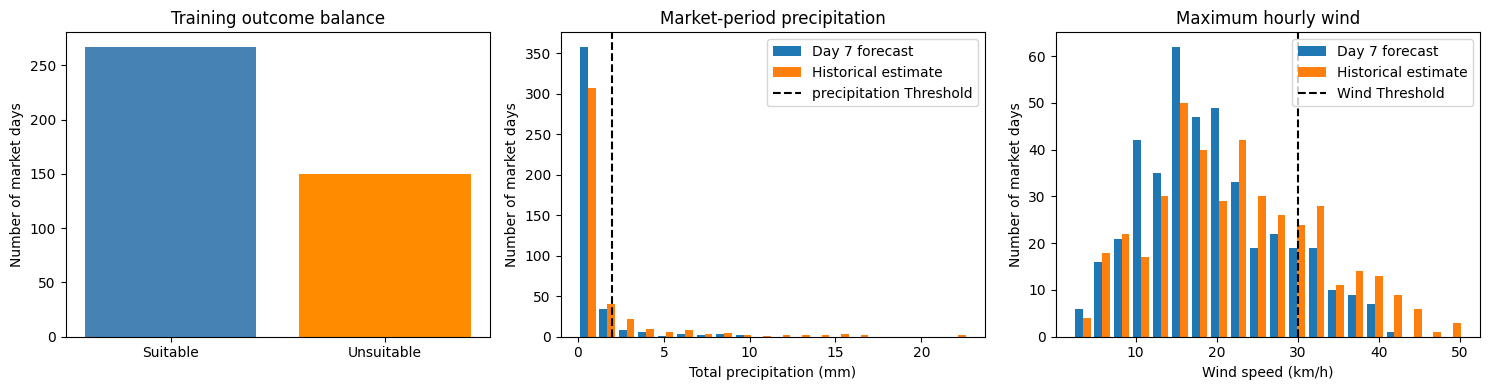

In [ ]:
# 2. Create three charts using training dates only
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Chart A: Outcome balance
axes[0].bar(
    ["Suitable", "Unsuitable"],
    training_counts.to_numpy(),
    color=["steelblue", "darkorange"]
)
axes[0].set_title("Training outcome balance")
axes[0].set_ylabel("Number of market days")

# Chart B: Forecast and historical precipitation
axes[1].hist(
    [
        train_data["forecast_precipitation_mm"],
        train_data["historical_precipitation_mm"]
    ],
    bins=20,
    label=["Day 7 forecast", "Historical estimate"]
)
axes[1].axvline(
    PRECIP_LIMIT_MM,
    color="black",
    linestyle="--",
    label="precipitation Threshold"
)
axes[1].set_title("Market-period precipitation")
axes[1].set_xlabel("Total precipitation (mm)")
axes[1].set_ylabel("Number of market days")
axes[1].legend()

# Chart C: Forecast and historical wind
axes[2].hist(
    [
        train_data["forecast_max_wind_kmh"],
        train_data["historical_max_wind_kmh"]
    ],
    bins=20,
    label=["Day 7 forecast", "Historical estimate"]
)
axes[2].axvline(
    WIND_LIMIT_KMH,
    color="black",
    linestyle="--",
    label="Wind Threshold"
)
axes[2].set_title("Maximum hourly wind")
axes[2].set_xlabel("Wind speed (km/h)")
axes[2].set_ylabel("Number of market days")
axes[2].legend()

plt.tight_layout()
plt.show()

### (7.3) Forecast Error

Calculate forecast errors using training observations only to help answer:

**"Why might we need a predictive model rather than simply trusting the Day-7 forecast?"**

- positive error = forecast underestimated the realised condition
- negative error = forecast overestimated the realised condition

In [ ]:
# Calculate forecast errors in the training period
train_data["precipitation_error"] = (
    train_data["historical_precipitation_mm"]
    - train_data["forecast_precipitation_mm"]
)

train_data["wind_error"] = (
    train_data["historical_max_wind_kmh"]
    - train_data["forecast_max_wind_kmh"]
)

error_summary = train_data[
    [
        "precipitation_error",
        "wind_error"
    ]
].describe().T

display(error_summary)

,count,mean,std,min,25%,50%,75%,max
precipitation_error,417.0,0.859233,3.225427,-7.100000,-0.100000,0.000000,0.700000,22.500000
wind_error,417.0,3.061768,8.253381,-23.789569,-2.644226,3.116016,8.371517,39.416332


In [ ]:
# Summarise forecast differences using training dates only
error_metrics = pd.DataFrame({
    "Measure": ["Precipitation", "Maximum hourly wind"],
    "Unit": ["mm", "km/h"],
    "Mean signed error": [
        train_data["precipitation_error"].mean(),
        train_data["wind_error"].mean(),
    ],
    "MAE": [
        train_data["precipitation_error"].abs().mean(),
        train_data["wind_error"].abs().mean(),
    ],
})

display(error_metrics.round(2))

,Measure,Unit,Mean signed error,MAE
0,Precipitation,mm,0.86,1.44
1,Maximum hourly wind,km/h,3.06,6.94


In [ ]:
print("Training days:", len(train_data))
print("First date:", train_data["market_date"].min())
print("Last date:", train_data["market_date"].max())

Training days: 417
First date: 2025-01-02 00:00:00
Last date: 2026-02-22 00:00:00


## (8) Feature Engineering

### (8.1)

Hourly Day 7 forecasts are summarised into one row for each complete market day. These features were created in Section 4.3.
| Feature | Calculation | Unit |
| :--- | :--- | :--- |
| `forecast_precipitation_mm` | Total predicted precipitation during the 10 am–4 pm market period | mm |
| `forecast_max_wind_kmh` | Highest predicted hourly wind-speed reading during the market period | km/h |

In [ ]:
FEATURES = [
    "forecast_precipitation_mm",
    "forecast_max_wind_kmh",
]

TARGET = "unsuitable"

X_train = train_data[FEATURES].copy()
y_train = train_data[TARGET].copy()

X_validation = validation_data[FEATURES].copy()
y_validation = validation_data[TARGET].copy()

X_test = test_data[FEATURES].copy()
y_test = test_data[TARGET].copy()

print("\nModelling datasets:")
print("Training rows:", len(X_train))
print("Validation rows:", len(X_validation))
print("Test rows:", len(X_test))

print("\nUnsuitable outcomes:")
print("Training:", int(y_train.sum()))
print("Validation:", int(y_validation.sum()))
print("Test:", int(y_test.sum()))


Modelling datasets:
Training rows: 417
Validation rows: 84
Test rows: 92

Unsuitable outcomes:
Training: 150
Validation: 13
Test: 23


## (9) Baseline Models

### (9.1) Simple Forecast Accuracy Against the Suitability Outcome

Two baseline approaches were establised to assess whether machine learning provides an improvement over simpler decision rules:

- Baseline 1 – Majority class: predicts the most common outcome observed in the training data for every validation date.
- Baseline 2 – Forecast rule: predicts a market date as unsuitable when the Day-7 forecast exceeds either the precipitation or wind threshold.

These provide benchmarks against which the machine-learning models can be evaluated.

Interpretation for market scheduling:

True Negative (TN): Correctly predicts a suitable market day.
True Positive (TP): Correctly warns that a market day will be unsuitable.
False Negative (FN) – "Missed unsuitable day": Actual conditions are unsuitable, but the model predicts suitable.
False Positive (FP) – "False alarm": The model predicts unsuitable, but actual conditions are suitable.


|                          |       Actually suitable |     Actually unsuitable |
| ------------------------ | ----------------------: | ----------------------: |
| **Predicted suitable**   |      True Negative (TN) | **False Negative (FN)** |
| **Predicted unsuitable** | **False Positive (FP)** |      True Positive (TP) |


Evaluation metrics:

Accuracy: proportion of all market days classified correctly.
Recall: proportion of genuinely unsuitable days correctly identified.
Precision: proportion of unsuitable warnings that were correct.
Specificity: proportion of genuinely suitable days correctly identified.
Balanced accuracy: average performance across the suitable and unsuitable classes (useful because the outcome classes are imbalanced).
F1 score: balances precision and recall.

Given the decision consequences defined in Section 2.5, attention is given to recall and missed unsuitable days, while also considering the number of false alarms generated.

In [ ]:
# Baseline 1: predict the most common training outcome (Majority class )
majority_class = int(y_train.mode().iloc[0])
majority_predictions = pd.Series(majority_class, index=y_validation.index)

# Baseline 2: predict unsuitable (1) when weather thresholds are exceeded.
forecast_rule_predictions = ((X_validation["forecast_precipitation_mm"] > PRECIP_LIMIT_MM)
    | (X_validation["forecast_max_wind_kmh"] > WIND_LIMIT_KMH)
).astype(int)

# ---------------------------------------------------------
# Evaluation function
#
# Target:
# 0 = Suitable
# 1 = Unsuitable
#
# FN = missed unsuitable day
# FP = false alarm
# ---------------------------------------------------------

def evaluate_predictions(name, y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    # Proportion of suitable days
    specificity = (tn / (tn + fp) if (tn + fp) > 0 else 0.0)

    # Proportion of unsuitable days
    false_negative_rate = (fn / (fn + tp) if (fn + tp) > 0 else 0.0)

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred), # average recall across the classes
        "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Specificity": specificity,
        "F1": f1_score( y_true, y_pred, pos_label=1, zero_division=0),
        "False-negative rate": false_negative_rate,
        "Missed unsuitable days": int(fn),
        "False alarms": int(fp),
        "Predicted unsuitable days": int((y_pred == 1).sum()),
    }


# Evaluate both baselines on the validation dataset
baseline_results = pd.DataFrame([evaluate_predictions("Majority class", y_validation, majority_predictions),
                                 evaluate_predictions("Forecast rule", y_validation, forecast_rule_predictions)]).set_index("Model")

print(
    f"Validation days: {len(y_validation)} | "
    f"Majority prediction: {majority_class} "
    f"(0=suitable, 1=unsuitable)"
)

display(baseline_results.round(3))

Validation days: 84 | Majority prediction: 0 (0=suitable, 1=unsuitable)


,Accuracy,Balanced accuracy,Precision,Recall,Specificity,F1,False-negative rate,Missed unsuitable days,False alarms,Predicted unsuitable days
Model,,,,,,,,,,
Majority class,0.845,0.500,0.000,0.000,1.000,0.000,1.000,13,0,0
Forecast rule,0.738,0.594,0.263,0.385,0.803,0.312,0.615,8,14,19


In [ ]:
# Summary of the results
majority_result = baseline_results.loc["Majority class"]
forecast_result = baseline_results.loc["Forecast rule"]

print(
    f"On {len(y_validation):,} validation days, the majority "
    f"baseline achieved {majority_result['Accuracy']:.1%} accuracy "
    f"and {majority_result['Recall']:.1%} recall, missing "
    f"{int(majority_result['Missed unsuitable days'])} unsuitable days "
    f"and producing {int(majority_result['False alarms'])} false alarms."
)

print(
    f"The forecast rule achieved "
    f"{forecast_result['Accuracy']:.1%} accuracy "
    f"and {forecast_result['Recall']:.1%} recall, missing "
    f"{int(forecast_result['Missed unsuitable days'])} unsuitable days "
    f"and producing {int(forecast_result['False alarms'])} false alarms."
)

On 84 validation days, the majority baseline achieved 84.5% accuracy and 0.0% recall, missing 13 unsuitable days and producing 0 false alarms.
The forecast rule achieved 73.8% accuracy and 38.5% recall, missing 8 unsuitable days and producing 14 false alarms.


On 236 validation days, the majority baseline achieved 75% accuracy but missed all 59 unsuitable days. The forecast rule achieved 75.4% accuracy, detecting only four unsuitable days, missing 55 and producing three false alarms. This shows why accuracy alone is insufficient: we need to detect more unsuitable days while keeping false alarms manageable.


## (10) ML Experiments

### (10.1) Experimental Approach

Three classification algorithms are initially evaluated:

- logistic regression
- random forest
- gradient boosting.
- Light GBM
- CatBoost

These provide a comparison between a linear probabilistic baseline, a bagging based tree model, and two gradient boosted tree models.

Models are evaluated using expanding-window validation. For each validation market date, the training window consists only of observations that would have been available by the Day-7 decision date. The training window expands as the validation period progresses, while future observations are excluded.

Each model produces an estimated probability of unsuitable weather. An initial probability threshold of 0.50 is used to convert these probabilities into suitable or unsuitable classifications. This threshold is used only for the initial model comparison and will be reviewed during the later decision-threshold and cost analysis.

Initial model performance is compared using accuracy, balanced accuracy, precision, recall, specificity and F1 score. Missed unsuitable days and false alarms are also reported to maintain alignment with the operational consequences defined in Section 2.5.

### (10.2) Development Data and Modelling Functions

Training and validation observations are combined into a development dataset for expanding window evaluation, while the test set remains excluded for final holdout assessment.

Reusable functions are defined to prepare each model, generate point-in-time validation predictions and summarise classification performance.

In [ ]:
# Experiment param settings
RANDOM_STATE = 77
INITIAL_PROBABILITY_THRESHOLD = 0.50
FORECAST_HORIZON_DAYS = 7

FEATURES = [
    "forecast_precipitation_mm",
    "forecast_max_wind_kmh",
]

TARGET = "unsuitable"
DATE_COLUMN = "market_date"


# Prep development data
'''
Notes
- test data exlcuded. Only used in final holdout

'''

development_data = pd.concat([train_data, validation_data,],ignore_index=True,)
development_data[DATE_COLUMN] = pd.to_datetime(development_data[DATE_COLUMN])
development_data = (development_data.sort_values(DATE_COLUMN).reset_index(drop=True))
validation_dates = (validation_data[DATE_COLUMN].sort_values().unique())
validation_dates = pd.to_datetime(validation_dates)

print("Development rows:", len(development_data))
print("Validation dates:", len(validation_dates))
print("First validation date:", validation_dates.min())
print("Last validation date:", validation_dates.max())

Development rows: 501
Validation dates: 84
First validation date: 2026-03-02 00:00:00
Last validation date: 2026-05-24 00:00:00


In [ ]:
# Create classification pipeline

'''
Notes
- any missing values are replaced with medians
- only uses training window
- sclaing is for logistic regression, not needed for tree models
'''

def create_classification_pipeline( model, scale_features=False):
    pipeline_steps = [("imputer", SimpleImputer(strategy="median"))]

    if scale_features:
        pipeline_steps.append(
            ("scaler", StandardScaler()))
    pipeline_steps.append(("model", model))

    return Pipeline(pipeline_steps)

In [ ]:
# Point-in-time expanding window evaluation

'''
Notes

For each val date:
1. set the decision date to seven days earlier.
2. train using obs available before that date.
3. predict the validation observation.
4. store the result.

'''

def run_expanded_window_classifier(
    data,
    feature_cols,
    target_col,
    date_col,
    validation_dates,
    model,
    algorithm_name,
    experiment_stage,
    probability_threshold=0.50,
    forecast_horizon_days=7
):
    results = []

    data = (data.copy().sort_values(date_col).reset_index(drop=True)    )
    data[date_col] = pd.to_datetime(data[date_col])
    validation_dates = pd.to_datetime(validation_dates)
    forecast_gap = pd.Timedelta(days=forecast_horizon_days)

    for forecast_date in validation_dates:

        # decision is made seven days before the market date
        decision_date = forecast_date - forecast_gap

        # only use outcomes available before the decision date
        train_window = data[data[date_col] < decision_date].copy()

        forecast_row = data[data[date_col] == forecast_date].copy()

        # Skip dates without exactly one forecast row
        if len(forecast_row) != 1:
            continue

        # A classifier requires observations from both classes
        if train_window[target_col].nunique() < 2:
            continue

        X_window_train = train_window[feature_cols].copy()
        y_window_train = train_window[ target_col].copy()
        X_next = forecast_row[feature_cols].copy()
        actual = int(forecast_row[target_col].iloc[0])
        fitted_model = clone(model)
        fitted_model.fit(X_window_train,y_window_train)

        unsuitable_probability = float(fitted_model.predict_proba(X_next)[0, 1])
        predicted = int( unsuitable_probability >= probability_threshold)

        results.append({
            "date": forecast_date,
            "decision_date": decision_date,
            "actual": actual,
            "predicted": predicted,
            "unsuitable_probability": unsuitable_probability,
            "correct": int(predicted == actual),
            "algorithm": algorithm_name,
            "experiment_stage": experiment_stage,
            "probability_threshold": probability_threshold,
            "n_features": len(feature_cols),
            "training_rows": len(train_window),
            "training_unsuitable_days": int(
                y_window_train.sum()
            ),
        })

    results_df = pd.DataFrame(results)

    if not results_df.empty:
        results_df = (results_df.sort_values("date").reset_index(drop=True))

    return results_df

In [ ]:
# Summarise classification performance for each model

def summarise_classification_results(results_df):
    summary_rows = []
    grouping_columns = ["experiment_stage", "algorithm"]

    for (experiment_stage, algorithm_name), group in results_df.groupby(grouping_columns):

        y_true = group["actual"]
        y_pred = group["predicted"]

        tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
        specificity = ( tn / (tn + fp) if (tn + fp) > 0 else 0.0)
        false_negative_rate = (fn / (fn + tp) if (fn + tp) > 0 else 0.0)

        summary_rows.append({
            "Experiment stage": experiment_stage,
            "Model": algorithm_name,
            "Validation predictions": len(group),
            "Accuracy": accuracy_score(y_true, y_pred),
            "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
            "Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
            "Specificity": specificity,
            "F1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
            "False-negative rate": false_negative_rate,
            "Missed unsuitable days": int(fn),
            "False alarms": int(fp),
            "Correct unsuitable warnings": int(tp),
            "Correct suitable predictions": int(tn),
            "Predicted unsuitable days": int(y_pred.sum()),
        })

    summary_df = pd.DataFrame(summary_rows)
    summary_df = (summary_df.sort_values(["Balanced accuracy", "Recall", "F1",],
                                         ascending=[False,False,False,]).reset_index(drop=True))
    summary_df.insert(0, "Rank", range(1, len(summary_df) + 1))

    return summary_df

### (10.3) Initial Models

The algorithms are first evaluated using initial specifications rather than tuned hyperparameters. This provides an initial comparison of modelling approaches before hyperparameter optimisation.

In [ ]:
# Initial classification models

initial_models = {
    "Logistic Regression":
        create_classification_pipeline(
            LogisticRegression(
                class_weight=None,
                max_iter=1000,
                random_state=RANDOM_STATE
            ),
            scale_features=True
        ),

    "Random Forest":
        create_classification_pipeline(
            RandomForestClassifier(
                n_estimators=200,
                max_depth=4,
                min_samples_leaf=5,
                class_weight=None,
                random_state=RANDOM_STATE,
                n_jobs=-1
            ),
            scale_features=False
        ),

    "Gradient Boosting":
        create_classification_pipeline(
            GradientBoostingClassifier(
                n_estimators=100,
                learning_rate=0.05,
                max_depth=2,
                min_samples_leaf=5,
                random_state=RANDOM_STATE
            ),
            scale_features=False
        ),

    "LightGBM":
        create_classification_pipeline(
            LGBMClassifier(
                n_estimators=100,
                learning_rate=0.05,
                max_depth=3,
                random_state=RANDOM_STATE,
                n_jobs=-1,
                verbosity=-1
            ),
            scale_features=False
        ),

    "CatBoost":
        create_classification_pipeline(
            CatBoostClassifier(
                iterations=100,
                learning_rate=0.05,
                depth=3,
                random_seed=RANDOM_STATE,
                verbose=False
            ),
            scale_features=False
        )
}

### (10.4) Expanded-Window Validation Results

Each initial model is evaluated across the same validation period using the expanded-window method. Performance is initially assessed using the 0.50 probability threshold.

In [ ]:
# Run expanding window validation for each model

initial_results_list = []

for algorithm_name, model in initial_models.items():

    algorithm_results = (
        run_expanded_window_classifier(
            data=development_data,
            feature_cols=FEATURES,
            target_col=TARGET,
            date_col=DATE_COLUMN,
            validation_dates=validation_dates,
            model=model,
            algorithm_name=algorithm_name,
            experiment_stage="Initial ML Model",
            probability_threshold=(INITIAL_PROBABILITY_THRESHOLD),
            forecast_horizon_days=(FORECAST_HORIZON_DAYS)
        )
    )

    initial_results_list.append(algorithm_results)

    print(
        f"Completed: {algorithm_name} | "
        f"Predictions: {len(algorithm_results)}"
    )


initial_ml_results = pd.concat(initial_results_list, ignore_index=True)
initial_ml_summary = (summarise_classification_results(initial_ml_results))

print()
print("Initial ML Model Comparison")

display(
    initial_ml_summary.style.format({
        "Accuracy": "{:.1%}",
        "Balanced accuracy": "{:.1%}",
        "Precision": "{:.1%}",
        "Recall": "{:.1%}",
        "Specificity": "{:.1%}",
        "F1": "{:.3f}",
        "False-negative rate": "{:.1%}",
    })
)

Completed: Logistic Regression | Predictions: 84
Completed: Random Forest | Predictions: 84
Completed: Gradient Boosting | Predictions: 84
Completed: LightGBM | Predictions: 84
Completed: CatBoost | Predictions: 84

Initial ML Model Comparison


,Rank,Experiment stage,Model,Validation predictions,Accuracy,Balanced accuracy,Precision,Recall,Specificity,F1,False-negative rate,Missed unsuitable days,False alarms,Correct unsuitable warnings,Correct suitable predictions,Predicted unsuitable days
0,1,Initial ML Model,CatBoost,84,73.8%,65.7%,30.4%,53.8%,77.5%,0.389,46.2%,6,16,7,55,23
1,2,Initial ML Model,Gradient Boosting,84,73.8%,65.7%,30.4%,53.8%,77.5%,0.389,46.2%,6,16,7,55,23
2,3,Initial ML Model,LightGBM,84,73.8%,65.7%,30.4%,53.8%,77.5%,0.389,46.2%,6,16,7,55,23
3,4,Initial ML Model,Logistic Regression,84,71.4%,64.2%,28.0%,53.8%,74.6%,0.368,46.2%,6,18,7,53,25
4,5,Initial ML Model,Random Forest,84,73.8%,62.5%,28.6%,46.2%,78.9%,0.353,53.8%,7,15,6,56,21


Validation Window Check

The validation windows are checked to confirm that each algorithm is evaluated over the same dates and therefore provides a consistent model comparison.

In [ ]:
# Confirm same dates

window_check = (initial_ml_results.groupby("algorithm").agg(
        predictions=("date", "size"),
        first_validation_date=("date", "min"),
        last_validation_date=("date", "max"),
        minimum_training_rows=("training_rows", "min"),
        maximum_training_rows=("training_rows", "max"),
    ).reset_index()
)

print("Expanded-window consistency check")
display(window_check)

Expanded-window consistency check


,algorithm,predictions,first_validation_date,last_validation_date,minimum_training_rows,maximum_training_rows
0,CatBoost,84,2026-03-02,2026-05-24,417,493
1,Gradient Boosting,84,2026-03-02,2026-05-24,417,493
2,LightGBM,84,2026-03-02,2026-05-24,417,493
3,Logistic Regression,84,2026-03-02,2026-05-24,417,493
4,Random Forest,84,2026-03-02,2026-05-24,417,493


### (10.5) Comparison with Baselines

To determine whether machine learning provides additional predictive value, the initial ML models are compared with the majority class and forecast rule baselines from Section 9.

For a consistent comparison, the baselines are recalculated using the validation dates successfully evaluated by all ML models. The approaches are then compared using the same classification metrics.

Models are initially ranked by balanced accuracy, with recall and F1 used as secondary ranking measures. This ranking is not treated as final model selection because probability calibration, decision thresholds, costs and hyperparameter tuning are assessed later.

In [ ]:
# get validation dates for every ML model

common_validation_dates = (initial_ml_results.groupby("date")["algorithm"].nunique())
common_validation_dates = common_validation_dates[common_validation_dates == len(initial_models)].index

# validation data for the common dates
baseline_comparison_data = (validation_data[validation_data[DATE_COLUMN].isin(common_validation_dates)].sort_values(DATE_COLUMN).copy())

baseline_comparison_actual = (baseline_comparison_data[TARGET])

# Recalculate Baseline 1: Majority class
majority_comparison_predictions = pd.Series(majority_class, index=baseline_comparison_data.index)

# Recalculate Baseline 2: Forecast rule
forecast_rule_comparison_predictions = ((baseline_comparison_data["forecast_precipitation_mm"] > PRECIP_LIMIT_MM) | (baseline_comparison_data["forecast_max_wind_kmh"] > WIND_LIMIT_KMH)).astype(int)

# Evaluate the baselines
baseline_comparison_results = pd.DataFrame([
    evaluate_predictions(
        "Majority class",
        baseline_comparison_actual,
        majority_comparison_predictions
    ),
    evaluate_predictions(
        "Forecast rule",
        baseline_comparison_actual,
        forecast_rule_comparison_predictions
    )
]).set_index("Model")

print("Baseline results on common validation dates")

display(
    baseline_comparison_results.style.format({
        "Accuracy": "{:.1%}",
        "Balanced accuracy": "{:.1%}",
        "Precision": "{:.1%}",
        "Recall": "{:.1%}",
        "Specificity": "{:.1%}",
        "F1": "{:.3f}",
        "False-negative rate": "{:.1%}",
    })
)

# baseline results for combined comparison
baseline_for_comparison = (baseline_comparison_results.reset_index().copy())
baseline_for_comparison["Model type"] = "Baseline"
baseline_for_comparison["Validation predictions"] = (len(baseline_comparison_data))

# ML results for combined comparison
ml_for_comparison = (initial_ml_summary.copy())
ml_for_comparison["Model type"] = "ML"

# Select columns for comparison
comparison_columns = [
    "Model type",
    "Model",
    "Validation predictions",
    "Accuracy",
    "Balanced accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "False-negative rate",
    "Missed unsuitable days",
    "False alarms",
    "Predicted unsuitable days",
]

# Combine baseline and ML results
model_comparison = pd.concat([baseline_for_comparison[comparison_columns], ml_for_comparison[comparison_columns],], ignore_index=True)


# Rank initial approaches

'''
Ranking Order
1. Balanced accuracy
2. Recall
3. F1
'''

model_comparison = (model_comparison.sort_values([
            "Balanced accuracy",
            "Recall",
            "F1",
        ],
        ascending=[
            False,
            False,
            False,
        ]
    ).reset_index(drop=True))

model_comparison.insert(0, "Rank", range(1, len(model_comparison) + 1))

# Display combined comparison
print("Baseline and Initial ML Model Comparison")

display(
    model_comparison.style
    .hide(axis="index")
    .format({
        "Accuracy": "{:.1%}",
        "Balanced accuracy": "{:.1%}",
        "Precision": "{:.1%}",
        "Recall": "{:.1%}",
        "Specificity": "{:.1%}",
        "F1": "{:.3f}",
        "False-negative rate": "{:.1%}",
    })
)

Baseline results on common validation dates


,Accuracy,Balanced accuracy,Precision,Recall,Specificity,F1,False-negative rate,Missed unsuitable days,False alarms,Predicted unsuitable days
Model,,,,,,,,,,
Majority class,84.5%,50.0%,0.0%,0.0%,100.0%,0.000,100.0%,13,0,0
Forecast rule,73.8%,59.4%,26.3%,38.5%,80.3%,0.312,61.5%,8,14,19


Baseline and Initial ML Model Comparison


Rank,Model type,Model,Validation predictions,Accuracy,Balanced accuracy,Precision,Recall,Specificity,F1,False-negative rate,Missed unsuitable days,False alarms,Predicted unsuitable days
1,ML,CatBoost,84,73.8%,65.7%,30.4%,53.8%,77.5%,0.389,46.2%,6,16,23
2,ML,Gradient Boosting,84,73.8%,65.7%,30.4%,53.8%,77.5%,0.389,46.2%,6,16,23
3,ML,LightGBM,84,73.8%,65.7%,30.4%,53.8%,77.5%,0.389,46.2%,6,16,23
4,ML,Logistic Regression,84,71.4%,64.2%,28.0%,53.8%,74.6%,0.368,46.2%,6,18,25
5,ML,Random Forest,84,73.8%,62.5%,28.6%,46.2%,78.9%,0.353,53.8%,7,15,21
6,Baseline,Forecast rule,84,73.8%,59.4%,26.3%,38.5%,80.3%,0.312,61.5%,8,14,19
7,Baseline,Majority class,84,84.5%,50.0%,0.0%,0.0%,100.0%,0.000,100.0%,13,0,0


### (10.6) Initial Results and Evaluation

** Add commentary on results **

These results are not used to select the final model at this stage. Subsequent sections consider the evaluation criteria in more detail, assess probability calibration, investigate the decision threshold and associated costs, and tune model hyperparameters before final holdout testing.

In [ ]:
# Summarise initial models and select highest ranked
best_initial_approach = model_comparison.iloc[0]

print(
    f"The highest-ranked initial approach was "
    f"{best_initial_approach['Model']} "
    f"({best_initial_approach['Model type']}). "
    f"It achieved "
    f"{best_initial_approach['Accuracy']:.1%} accuracy, "
    f"{best_initial_approach['Balanced accuracy']:.1%} "
    f"balanced accuracy and "
    f"{best_initial_approach['Recall']:.1%} recall. "
    f"It missed "
    f"{int(best_initial_approach['Missed unsuitable days'])} "
    f"unsuitable days and produced "
    f"{int(best_initial_approach['False alarms'])} "
    f"false alarms."
)

The highest-ranked initial approach was CatBoost (ML). It achieved 73.8% accuracy, 65.7% balanced accuracy and 53.8% recall. It missed 6 unsuitable days and produced 16 false alarms.


## (11) Model Performance - Initial Diagnostics

### (11.1) Discrimination (Gini)

Discrimination assesses whether a model assigns higher predicted risk to unsuitable market days than to suitable days. It is evaluated using ROC-AUC and the corresponding Gini coefficient.

ROC-AUC measures the model's ability to rank unsuitable outcomes above suitable outcomes, while Gini expresses the same ranking performance using:

$$Gini = 2 \times ROC\text{-}AUC - 1$$

Higher values indicate stronger discrimination. These measures evaluate ranking ability independently of the 0.50 classification threshold.

The ML models are compared with the majority class and forecast rule baselines using the same validation observations.
- For the ML models, discrimination is assessed using predicted probabilities.
- The baselines produce discrete classifications rather than continuous probabilities so their Gini values are included as benchmark comparisons rather than direct equivalent probability ranking measures.

In [ ]:
# Discrimination performance

discrimination_results = []

# ML models
ml_discrimination_data = initial_ml_results[initial_ml_results["date"].isin(common_validation_dates)].copy()

for algorithm_name, group in ml_discrimination_data.groupby("algorithm"):

    y_true = group["actual"]
    y_score = group["unsuitable_probability"]
    roc_auc = roc_auc_score(y_true, y_score)
    gini = 2 * roc_auc - 1

    discrimination_results.append({
        "Model type": "ML",
        "Model": algorithm_name,
        "ROC-AUC": roc_auc,
        "Gini": gini,
    })

# Majority class baseline
majority_auc = roc_auc_score(baseline_comparison_actual, majority_comparison_predictions)
discrimination_results.append({
    "Model type": "Baseline",
    "Model": "Majority class",
    "ROC-AUC": majority_auc,
    "Gini": 2 * majority_auc - 1,
})

# Forecast rule baseline
forecast_rule_auc = roc_auc_score(baseline_comparison_actual, forecast_rule_comparison_predictions)
discrimination_results.append({
    "Model type": "Baseline",
    "Model": "Forecast rule",
    "ROC-AUC": forecast_rule_auc,
    "Gini": 2 * forecast_rule_auc - 1,
})

# comparison table
discrimination_summary = (pd.DataFrame(discrimination_results).sort_values("Gini", ascending=False).reset_index(drop=True))
discrimination_summary.insert(0, "Rank", range(1, len(discrimination_summary) + 1))

display(discrimination_summary.style.hide(axis="index").format({
        "ROC-AUC": "{:.3f}",
        "Gini": "{:.3f}",
    })
)

Rank,Model type,Model,ROC-AUC,Gini
1,ML,Random Forest,0.666,0.333
2,ML,CatBoost,0.659,0.317
3,ML,Logistic Regression,0.653,0.307
4,ML,Gradient Boosting,0.653,0.306
5,ML,LightGBM,0.640,0.281
6,Baseline,Forecast rule,0.594,0.187
7,Baseline,Majority class,0.500,0.000


#### (11.1.1) Probability Distributions

The model produces a predicted probability of unsuitable weather for each market day. The initial 0.50 decision threshold converts this probability into a classification:

- Below 0.50: predicted suitable
- 0.50 or above: predicted unsuitable

The coloured distributions show the predicted probabilities for suitable and unsuitable outcomes respectively. Ideally, suitable days would be concentrated below the threshold and unsuitable days above it. Overlap between the distributions represents observations that are more difficult for the model to distinguish.

The 0.50 threshold is used only for the initial comparison and is not assumed to be optimal. Alternative thresholds are assessed later based on the trade-off between missed unsuitable days and false alarms.

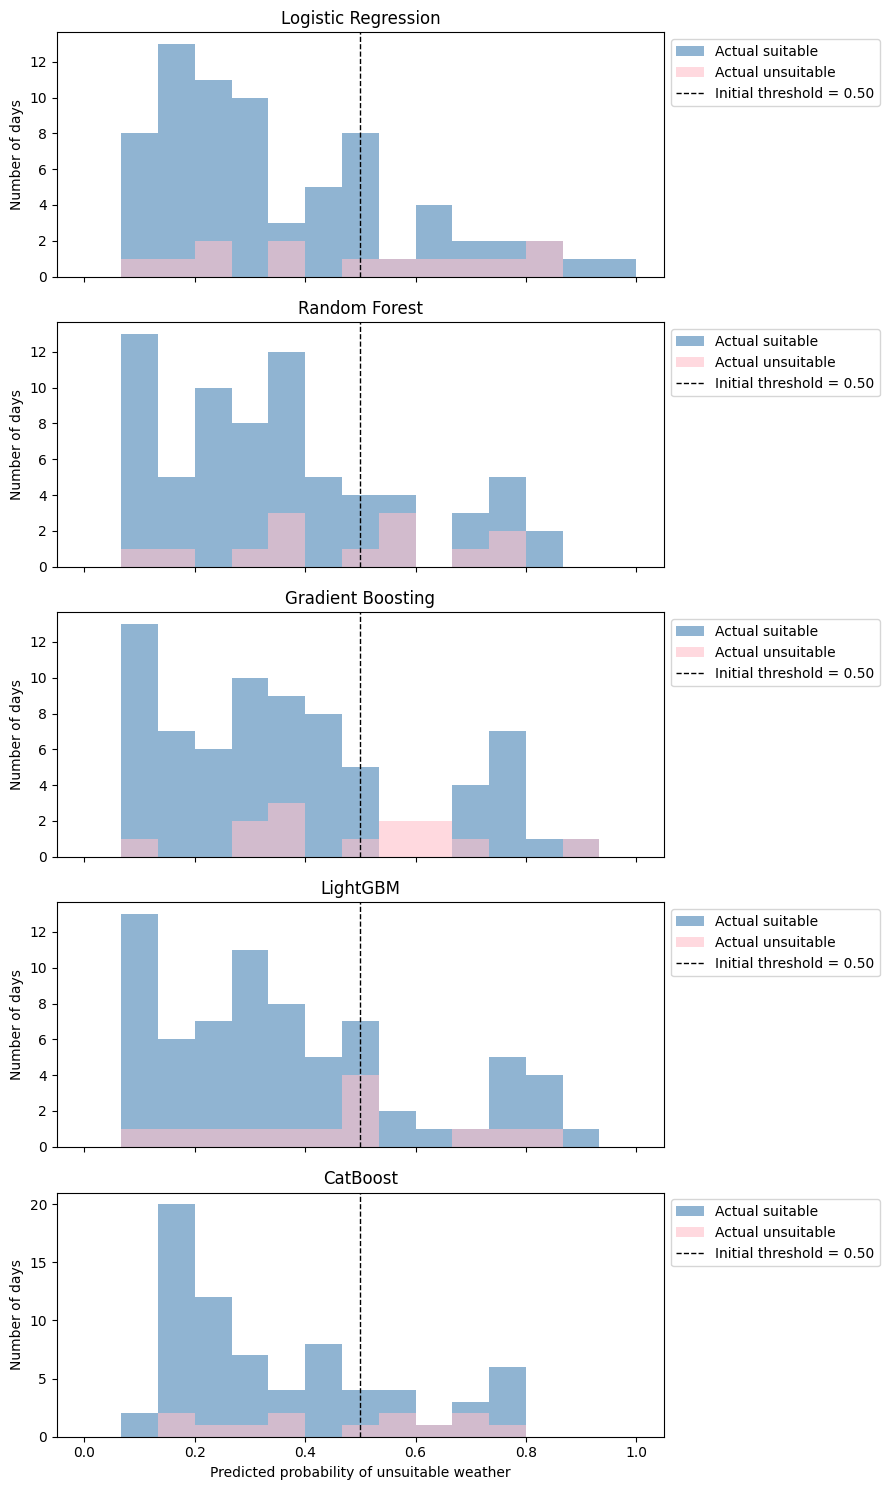

In [ ]:
# Predicted probability distributions by actual outcome

models = ml_discrimination_data["algorithm"].unique()
fig, axes = plt.subplots(len(models), 1, figsize=(9, 3 * len(models)), sharex=True)

if len(models) == 1:
    axes = [axes]

for ax, model_name in zip(axes, models):

    model_data = ml_discrimination_data[ml_discrimination_data["algorithm"] == model_name]
    suitable = model_data.loc[model_data["actual"] == 0, "unsuitable_probability"]

    unsuitable = model_data.loc[model_data["actual"] == 1, "unsuitable_probability"]

    ax.hist(
        suitable,
        bins=15,
        range=(0, 1),
        alpha=0.6,
        color="steelblue",
        label="Actual suitable"
    )

    ax.hist(
        unsuitable,
        bins=15,
        range=(0, 1),
        alpha=0.6,
        color="pink",
        label="Actual unsuitable"
    )

    ax.axvline(
        INITIAL_PROBABILITY_THRESHOLD,
        color="black",
        linestyle="--",
        linewidth=1.0,
        label=(
            f"Initial threshold = "
            f"{INITIAL_PROBABILITY_THRESHOLD:.2f}"
        )
    )

    ax.set_title(model_name)
    ax.set_ylabel("Number of days")
    ax.legend(bbox_to_anchor=(1.0, 1), loc="upper left")

axes[-1].set_xlabel("Predicted probability of unsuitable weather")
plt.tight_layout()
plt.show()

### (11.2) Calibration

Background & Approach

- The initial 0.50 threshold used in Section 10 converts model probabilities into suitable or unsuitable classifications, but the probabilities themselves are important because they represent the estimated risk of unsuitable market conditions.

- Calibration assesses whether predicted risks are consistent with the observed frequency of unsuitable weather.

- Calibration is evaluated using the expanding-window validation predictions. Brier score is used to measure probability accuracy, while calibration curves compare predicted risk with the observed proportion of unsuitable days.

- Lower Brier scores and calibration curves closer to the 45-degree reference line indicate better-calibrated probabilities. The test set remains excluded.

#### (11.2.1) Brier Score

Brier score measures the mean squared difference between each predicted probability and the actual binary outcome.

$$\text{Brier Score} = \text{Average}(Predicted\ Probability - Actual\ Outcome)^2$$

A lower score indicates more accurate probability estimates. A score of zero represents perfect predictions.

In [ ]:
from sklearn.metrics import brier_score_loss

brier_results = []

calibration_data = initial_ml_results[initial_ml_results["date"].isin(common_validation_dates)].copy()

for algorithm_name, group in calibration_data.groupby("algorithm"):

    y_true = group["actual"]
    y_prob = group["unsuitable_probability"]
    brier_score = brier_score_loss(y_true, y_prob)

    brier_results.append({
        "Model": algorithm_name,
        "Brier score": brier_score,
        "Mean predicted risk": y_prob.mean(),
        "Actual unsuitable rate": y_true.mean(),
    })

brier_summary = (pd.DataFrame(brier_results).sort_values("Brier score", ascending=True).reset_index(drop=True))
brier_summary.insert(0, "Rank", range(1, len(brier_summary) + 1))

display(brier_summary.style.hide(axis="index").format({
        "Brier score": "{:.3f}",
        "Mean predicted risk": "{:.1%}",
        "Actual unsuitable rate": "{:.1%}",
    })
)

Rank,Model,Brier score,Mean predicted risk,Actual unsuitable rate
1,CatBoost,0.190,37.0%,15.5%
2,Random Forest,0.197,38.1%,15.5%
3,Logistic Regression,0.201,37.7%,15.5%
4,Gradient Boosting,0.205,38.9%,15.5%
5,LightGBM,0.211,38.6%,15.5%


It shows every model is, on average, predicting higher unsuitable weather than what actually occurred.

#### (11.2.2) Calibration Curves

In [ ]:
from sklearn.calibration import calibration_curve

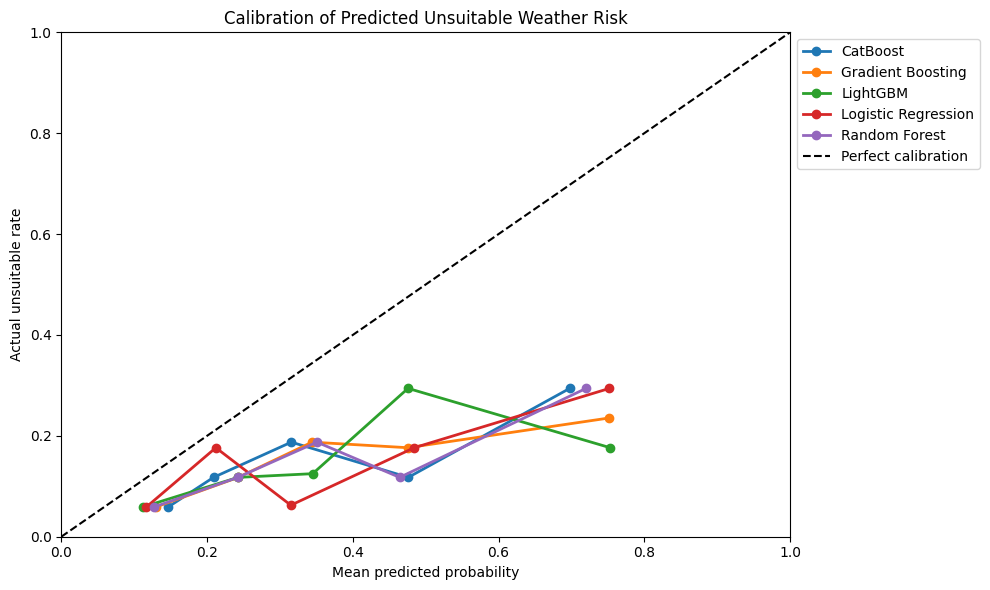

In [ ]:
plt.figure(figsize=(10, 6))

for algorithm_name, group in calibration_data.groupby("algorithm"):

    observed_rate, mean_predicted_probability = calibration_curve(
        group["actual"],
        group["unsuitable_probability"],
        n_bins=5,
        strategy="quantile" # splits predictions into groups with similar num of obs
    )

    plt.plot(
        mean_predicted_probability,
        observed_rate,
        marker="o",
        linewidth=2,
        label=algorithm_name
    )

# Perfect calibration reference line
plt.plot(
    [0, 1],
    [0, 1],
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Actual unsuitable rate")
plt.title("Calibration of Predicted Unsuitable Weather Risk")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.0, 1), loc="upper left")
plt.tight_layout()
plt.show()

The models generally assign probabilities of unsuitable weather that are higher than the proportion of unsuitable days actually observed.

This is consistent with the Brier results where:

- Mean predicted risk: roughly 37–39%
- Observed unsuitable rate: 15.5%

For example, around a mean predicted probability of 0.5, the chart shows observed unsuitable rates mostly around 0.12–0.30, rather than 0.5.

So the models appear to have some ability to vary risk, but their absolute probabilities are too high.

Overall, the results suggest that recalibration may be beneficial before the probabilities are used in estimates.

### (11.3) Initial Diagnostic Summary

In [ ]:
# ---------------------------------------------------------
# Overall probability performance summary
# ---------------------------------------------------------

model_performance_summary = (
    discrimination_summary[
        [
            "Model",
            "ROC-AUC",
            "Gini",
        ]
    ]
    .merge(
        brier_summary[
            [
                "Model",
                "Brier score",
            ]
        ],
        on="Model",
        how="inner"
    )
)

# Display
display(model_performance_summary.style.hide(axis="index").format({
        "ROC-AUC": "{:.3f}",
        "Gini": "{:.3f}",
        "Brier score": "{:.3f}"
        # "Predicted rate": "{:.1%}",
        # "Observed rate": "{:.1%}",
        # "O/E ratio": "{:.2f}",
        # "O/E deviation": "{:.2f}",
    })
)

Model,ROC-AUC,Gini,Brier score
Random Forest,0.666,0.333,0.197
CatBoost,0.659,0.317,0.190
Logistic Regression,0.653,0.307,0.201
Gradient Boosting,0.653,0.306,0.205
LightGBM,0.640,0.281,0.211


In [ ]:
# Dynamic interpretation

best_gini = (model_performance_summary.sort_values("Gini", ascending=False).iloc[0])
best_brier = ( model_performance_summary.sort_values("Brier score", ascending=True).iloc[0])

print(
    f"{best_gini['Model']} achieved the strongest initial "
    f"discrimination, with a Gini coefficient of "
    f"{best_gini['Gini']:.3f} and ROC-AUC of "
    f"{best_gini['ROC-AUC']:.3f}. "
    f"{best_brier['Model']} achieved the lowest Brier score "
    f"of {best_brier['Brier score']:.3f}, indicating the strongest "
    f"initial probability accuracy."
)

if best_gini["Model"] == best_brier["Model"]:
    print(
        f"{best_gini['Model']} therefore produced both the strongest "
        f"discrimination and the lowest Brier score among the initial "
        f"model specifications."
    )
else:
    print(
        "The model with the strongest discrimination was not the same "
        "as the model with the lowest Brier score. This highlights the "
        "difference between ranking risk effectively and producing "
        "accurate probability estimates."
    )

print(
    "These results provide a pre-tuning benchmark rather than final "
    "model selection. Model performance will be reassessed after "
    "hyperparameter tuning."
)

Random Forest achieved the strongest initial discrimination, with a Gini coefficient of 0.333 and ROC-AUC of 0.666. CatBoost achieved the lowest Brier score of 0.190, indicating the strongest initial probability accuracy.
The model with the strongest discrimination was not the same as the model with the lowest Brier score. This highlights the difference between ranking risk effectively and producing accurate probability estimates.
These results provide a pre-tuning benchmark rather than final model selection. Model performance will be reassessed after hyperparameter tuning.


## (12) Hyperparameter Tuning

(12.1) Tuning Approach

Hyperparameter tuning is done using the same expanding window validation framework applied to the initial models. Each candidate parameter combination is evaluated using only the observations that would have been available before each Day-7 decision date.

** confirm primary metrics used for ranking **

ROC-AUC is used as the primary tuning measure because it assesses probability ranking independently of the initial 0.50 classification threshold. Brier score is used as a secondary criterion to favour more accurate probability estimates where discrimination is similar.

Classification metrics calculated at the 0.50 threshold are retained for diagnostic purposes, but the operational threshold is optimised separately in the subsequent decision threshold and cost analysis. The test set remains excluded.

In [ ]:
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# Hyperparameter tuning settings

TUNING_ITERATIONS = 20

TUNING_PROBABILITY_THRESHOLD = (INITIAL_PROBABILITY_THRESHOLD)

In [ ]:
# function to tune classification models using expanding window validation

def tune_expanding_window_classifier(
    base_model,
    parameter_distributions,
    data,
    feature_cols,
    target_col,
    date_col,
    validation_dates,
    algorithm_name,
    n_iter=20,
    random_state=77,
    probability_threshold=0.50,
    forecast_horizon_days=7,
):

    tuning_results = []

    parameter_candidates = list(ParameterSampler(parameter_distributions, n_iter=n_iter, random_state=random_state))

    print(
        f"Tuning {algorithm_name}: "
        f"{len(parameter_candidates)} iterations"
    )

    for candidate_number, parameters in enumerate(
        parameter_candidates,
        start=1
    ):
        candidate_model = clone(base_model)
        candidate_model.set_params(**parameters)
        candidate_predictions = (
            run_expanded_window_classifier(
                data=data,
                feature_cols=feature_cols,
                target_col=target_col,
                date_col=date_col,
                validation_dates=validation_dates,
                model=candidate_model,
                algorithm_name=algorithm_name,
                experiment_stage="Hyperparameter Tuning",
                probability_threshold=probability_threshold,
                forecast_horizon_days=forecast_horizon_days
            )
        )

        if candidate_predictions.empty:
            continue

        y_true = candidate_predictions["actual"]
        y_prob = candidate_predictions["unsuitable_probability"]
        y_pred = candidate_predictions["predicted"]

        # Skip candidates where AUC cannot be calculated
        if y_true.nunique() < 2:
            continue

        roc_auc = roc_auc_score(y_true, y_prob)
        gini = 2 * roc_auc - 1
        brier_score = brier_score_loss(y_true, y_prob)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
        specificity = (tn / (tn + fp) if (tn + fp) > 0 else 0.0)
        balanced_accuracy = balanced_accuracy_score(y_true, y_pred)
        precision = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
        recall = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
        f1 = f1_score(y_true, y_pred, pos_label=1, zero_division=0)

        tuning_results.append({
            "Algorithm": algorithm_name,
            "Candidate": candidate_number,
            "Validation predictions": len(candidate_predictions),
            "ROC-AUC": roc_auc,
            "Gini": gini,
            "Brier score": brier_score,
            "Balanced accuracy": balanced_accuracy,
            "Precision": precision,
            "Recall": recall,
            "Specificity": specificity,
            "F1": f1,
            "Missed unsuitable days": int(fn),
            "False alarms": int(fp),
            "Parameters": parameters,
        })

        # print(
        #     f"{algorithm_name} | "
        #     f"Candidate {candidate_number}/"
        #     f"{len(parameter_candidates)} | "
        #     f"AUC: {roc_auc:.3f} | "
        #     f"Brier: {brier_score:.3f}"
        # )
        print(
            f"{algorithm_name} | "
            f"Candidate {candidate_number}/"
            f"{len(parameter_candidates)} | "
            f"AUC: {roc_auc:.3f} | "
            f"Brier: {brier_score:.3f} | "
            f"Balanced accuracy: {balanced_accuracy:.1%} | "
            f"Recall: {recall:.1%} | "
            f"F1: {f1:.3f}"
        )

    tuning_results_df = pd.DataFrame(tuning_results)

    if tuning_results_df.empty:
        raise ValueError(
            f"No valid tuning results were produced for "
            f"{algorithm_name}."
        )

    # Primary ranking: highest balanced accuracy
    # Tie-breaker 1: highest recall of unsuitable days
    # Tie-breaker 2: highest F1 score

    # tuning_results_df = (
    #     tuning_results_df
    #     .sort_values(
    #         [
    #             "ROC-AUC",
    #             "Brier score",
    #             "Recall",
    #         ],
    #         ascending=[
    #             False,
    #             True,
    #             False,
    #         ]
    #     )
    #     .reset_index(drop=True)
    # )

    tuning_results_df = (
        tuning_results_df
        .sort_values(
            [
                "ROC-AUC",
                "Brier score",
                "Balanced accuracy",
            ],
            ascending=[
                False,
                False,
                False,
            ]
        )
        .reset_index(drop=True)
    )

    tuning_results_df.insert(0, "Rank", range(1, len(tuning_results_df) + 1))
    best_parameters = (tuning_results_df.iloc[0]["Parameters"])
    best_model = clone(base_model)
    best_model.set_params(**best_parameters)

    return (best_model, best_parameters, tuning_results_df)

### (12.2) Logistic Regression Tuning

In [ ]:
base_model_random_forest = create_classification_pipeline(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    scale_features=False
)

parameter_distributions_random_forest = {
    "model__n_estimators": [50, 100, 200],
    "model__max_depth": [3, 4, 5, 8],
    "model__min_samples_leaf": [2, 5, 10],
    "model__class_weight": [None, "balanced"]
}

(
    best_model_random_forest,
    best_params_random_forest,
    tuning_results_random_forest,
) = tune_expanding_window_classifier(
    base_model=base_model_random_forest,
    parameter_distributions=parameter_distributions_random_forest,
    data=development_data,
    feature_cols=FEATURES,
    target_col=TARGET,
    date_col=DATE_COLUMN,
    validation_dates=validation_dates,
    algorithm_name="Random Forest",
    n_iter=TUNING_ITERATIONS,
    random_state=RANDOM_STATE,
    probability_threshold=TUNING_PROBABILITY_THRESHOLD,
    forecast_horizon_days=FORECAST_HORIZON_DAYS
)

print("\nBest Random Forest parameters:")
print(best_params_random_forest)

display(
    tuning_results_random_forest.head(10).style
    .hide(axis="index")
    .format({
        "ROC-AUC": "{:.3f}",
        "Gini": "{:.3f}",
        "Brier score": "{:.3f}",
        "Balanced accuracy": "{:.1%}",
        "Precision": "{:.1%}",
        "Recall": "{:.1%}",
        "Specificity": "{:.1%}",
        "F1": "{:.3f}",
    })
)

Tuning Random Forest: 20 iterations
Random Forest | Candidate 1/20 | AUC: 0.611 | Brier: 0.270 | Balanced accuracy: 55.1% | Recall: 53.8% | F1: 0.275
Random Forest | Candidate 2/20 | AUC: 0.675 | Brier: 0.249 | Balanced accuracy: 61.4% | Recall: 69.2% | F1: 0.327
Random Forest | Candidate 3/20 | AUC: 0.673 | Brier: 0.255 | Balanced accuracy: 62.1% | Recall: 69.2% | F1: 0.333
Random Forest | Candidate 4/20 | AUC: 0.675 | Brier: 0.184 | Balanced accuracy: 65.7% | Recall: 53.8% | F1: 0.389
Random Forest | Candidate 5/20 | AUC: 0.661 | Brier: 0.263 | Balanced accuracy: 60.0% | Recall: 69.2% | F1: 0.316
Random Forest | Candidate 6/20 | AUC: 0.616 | Brier: 0.270 | Balanced accuracy: 55.1% | Recall: 53.8% | F1: 0.275
Random Forest | Candidate 7/20 | AUC: 0.614 | Brier: 0.220 | Balanced accuracy: 60.4% | Recall: 46.2% | F1: 0.324
Random Forest | Candidate 8/20 | AUC: 0.633 | Brier: 0.270 | Balanced accuracy: 62.8% | Recall: 69.2% | F1: 0.340
Random Forest | Candidate 9/20 | AUC: 0.650 | Brier:

KeyboardInterrupt: 

In [ ]:
# Logistic Regression tuning

base_model_logistic = (create_classification_pipeline(LogisticRegression(
    class_weight=None,
    max_iter=2000,
    random_state=RANDOM_STATE
    ),
    scale_features=True
    )
)

# main tuning param to contorl regularisation in log reg - smaller = simpler model/underfitting, larger = more complex/overfitting
# class weight added for imbalanced data
parameter_distributions_logistic = {
    "model__C": [0.001, 0.01, 0.03, 0.10, 0.30, 1.00, 3.00, 10.00, 30.00, 100.00],
    "model__class_weight": [None, "balanced"]
    }

(
    best_model_logistic, best_params_logistic, tuning_results_logistic) = tune_expanding_window_classifier(
    base_model=base_model_logistic,
    parameter_distributions=(parameter_distributions_logistic),
    data=development_data,
    feature_cols=FEATURES,
    target_col=TARGET,
    date_col=DATE_COLUMN,
    validation_dates=validation_dates,
    algorithm_name="Logistic Regression",
    n_iter=len(parameter_distributions_logistic["model__C"]) * len(parameter_distributions_logistic["model__class_weight"]),
    random_state=RANDOM_STATE,
    probability_threshold=(TUNING_PROBABILITY_THRESHOLD),
    forecast_horizon_days=(FORECAST_HORIZON_DAYS)
)

print("\nBest Logistic Regression parameters:")
print(best_params_logistic)

display(tuning_results_logistic.head(99).style.hide(axis="index").format({
    "ROC-AUC": "{:.3f}",
    "Gini": "{:.3f}",
    "Brier score": "{:.3f}",
    "Balanced accuracy": "{:.1%}",
    "Precision": "{:.1%}",
    "Recall": "{:.1%}",
    "Specificity": "{:.1%}",
    "F1": "{:.3f}",
    })
)

Tuning Logistic Regression: 20 iterations
Logistic Regression | Candidate 1/20 | AUC: 0.615 | Brier: 0.166 | Balanced accuracy: 50.0% | Recall: 0.0% | F1: 0.000
Logistic Regression | Candidate 2/20 | AUC: 0.663 | Brier: 0.247 | Balanced accuracy: 61.8% | Recall: 61.5% | F1: 0.333
Logistic Regression | Candidate 3/20 | AUC: 0.658 | Brier: 0.173 | Balanced accuracy: 63.6% | Recall: 38.5% | F1: 0.385
Logistic Regression | Candidate 4/20 | AUC: 0.660 | Brier: 0.248 | Balanced accuracy: 61.8% | Recall: 61.5% | F1: 0.333
Logistic Regression | Candidate 5/20 | AUC: 0.658 | Brier: 0.184 | Balanced accuracy: 64.6% | Recall: 46.2% | F1: 0.387
Logistic Regression | Candidate 6/20 | AUC: 0.659 | Brier: 0.256 | Balanced accuracy: 61.1% | Recall: 61.5% | F1: 0.327
Logistic Regression | Candidate 7/20 | AUC: 0.654 | Brier: 0.194 | Balanced accuracy: 66.4% | Recall: 53.8% | F1: 0.400
Logistic Regression | Candidate 8/20 | AUC: 0.657 | Brier: 0.265 | Balanced accuracy: 61.1% | Recall: 61.5% | F1: 0.327

Rank,Algorithm,Candidate,Validation predictions,ROC-AUC,Gini,Brier score,Balanced accuracy,Precision,Recall,Specificity,F1,Missed unsuitable days,False alarms,Parameters
1,Logistic Regression,2,84,0.663,0.326,0.247,61.8%,22.9%,61.5%,62.0%,0.333,5,27,"{'model__class_weight': 'balanced', 'model__C': 0.001}"
2,Logistic Regression,4,84,0.660,0.320,0.248,61.8%,22.9%,61.5%,62.0%,0.333,5,27,"{'model__class_weight': 'balanced', 'model__C': 0.01}"
3,Logistic Regression,6,84,0.659,0.317,0.256,61.1%,22.2%,61.5%,60.6%,0.327,5,28,"{'model__class_weight': 'balanced', 'model__C': 0.03}"
4,Logistic Regression,5,84,0.658,0.315,0.184,64.6%,33.3%,46.2%,83.1%,0.387,7,12,"{'model__class_weight': None, 'model__C': 0.03}"
5,Logistic Regression,3,84,0.658,0.315,0.173,63.6%,38.5%,38.5%,88.7%,0.385,8,8,"{'model__class_weight': None, 'model__C': 0.01}"
6,Logistic Regression,8,84,0.657,0.313,0.265,61.1%,22.2%,61.5%,60.6%,0.327,5,28,"{'model__class_weight': 'balanced', 'model__C': 0.1}"
7,Logistic Regression,10,84,0.655,0.311,0.269,61.1%,22.2%,61.5%,60.6%,0.327,5,28,"{'model__class_weight': 'balanced', 'model__C': 0.3}"
8,Logistic Regression,20,84,0.654,0.309,0.271,61.1%,22.2%,61.5%,60.6%,0.327,5,28,"{'model__class_weight': 'balanced', 'model__C': 100.0}"
9,Logistic Regression,18,84,0.654,0.309,0.271,61.1%,22.2%,61.5%,60.6%,0.327,5,28,"{'model__class_weight': 'balanced', 'model__C': 30.0}"
10,Logistic Regression,16,84,0.654,0.309,0.271,61.1%,22.2%,61.5%,60.6%,0.327,5,28,"{'model__class_weight': 'balanced', 'model__C': 10.0}"


### (12.3) Random Forest Tuning

In [ ]:
# Random Forest tuning

warnings.filterwarnings(
    "ignore",
    message=r".*sklearn\.utils\.parallel\.delayed.*"
)

base_model_random_forest = (create_classification_pipeline(RandomForestClassifier(
    class_weight=None,
    random_state=RANDOM_STATE,
    n_jobs=-1
    ),
    scale_features=False
    )
)

# Smaller search for initial tuning
parameter_distributions_random_forest = {
    "model__n_estimators": [50, 100],
    "model__max_depth": [4, 6, None],
    "model__min_samples_leaf": [3, 5, 7],
    "model__min_samples_split": [5, 10],
    "model__max_features": ["sqrt"],
    "model__class_weight": [None, "balanced"]
}

# initial model
#   "Random Forest":
#         create_classification_pipeline(
#             RandomForestClassifier(
#                 n_estimators=200,
#                 max_depth=4,
#                 min_samples_leaf=5,
#                 class_weight=None,
#                 random_state=RANDOM_STATE,
#                 n_jobs=-1
#             ),
#             scale_features=False
#         ),

(
    best_model_random_forest,
    best_params_random_forest,
    tuning_results_random_forest,
) = tune_expanding_window_classifier(
    base_model=base_model_random_forest,
    parameter_distributions=(parameter_distributions_random_forest),
    data=development_data,
    feature_cols=FEATURES,
    target_col=TARGET,
    date_col=DATE_COLUMN,
    validation_dates=validation_dates,
    algorithm_name="Random Forest",
    n_iter=TUNING_ITERATIONS,
    random_state=RANDOM_STATE,
    probability_threshold=(TUNING_PROBABILITY_THRESHOLD),
    forecast_horizon_days=(FORECAST_HORIZON_DAYS)
)

print("\nBest Random Forest parameters:")
print(best_params_random_forest)

display(
    tuning_results_random_forest.head(10).style
    .hide(axis="index")
    .format({
        "ROC-AUC": "{:.3f}",
        "Gini": "{:.3f}",
        "Brier score": "{:.3f}",
        "Balanced accuracy": "{:.1%}",
        "Precision": "{:.1%}",
        "Recall": "{:.1%}",
        "Specificity": "{:.1%}",
        "F1": "{:.3f}",
    })
)

Tuning Random Forest: 20 iterations
Random Forest | Candidate 1/20 | AUC: 0.614 | Brier: 0.279 | Balanced accuracy: 62.1% | Recall: 69.2% | F1: 0.333
Random Forest | Candidate 2/20 | AUC: 0.671 | Brier: 0.258 | Balanced accuracy: 65.9% | Recall: 76.9% | F1: 0.364
Random Forest | Candidate 3/20 | AUC: 0.637 | Brier: 0.271 | Balanced accuracy: 60.7% | Recall: 69.2% | F1: 0.321
Random Forest | Candidate 4/20 | AUC: 0.653 | Brier: 0.197 | Balanced accuracy: 65.7% | Recall: 53.8% | F1: 0.389
Random Forest | Candidate 5/20 | AUC: 0.640 | Brier: 0.270 | Balanced accuracy: 60.0% | Recall: 69.2% | F1: 0.316
Random Forest | Candidate 6/20 | AUC: 0.627 | Brier: 0.275 | Balanced accuracy: 62.1% | Recall: 69.2% | F1: 0.333
Random Forest | Candidate 7/20 | AUC: 0.634 | Brier: 0.222 | Balanced accuracy: 61.1% | Recall: 46.2% | F1: 0.333
Random Forest | Candidate 8/20 | AUC: 0.631 | Brier: 0.272 | Balanced accuracy: 56.8% | Recall: 61.5% | F1: 0.291
Random Forest | Candidate 9/20 | AUC: 0.636 | Brier:

Rank,Algorithm,Candidate,Validation predictions,ROC-AUC,Gini,Brier score,Balanced accuracy,Precision,Recall,Specificity,F1,Missed unsuitable days,False alarms,Parameters
1,Random Forest,2,84,0.671,0.341,0.258,65.9%,23.8%,76.9%,54.9%,0.364,3,32,"{'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 5, 'model__max_features': 'sqrt', 'model__max_depth': 4, 'model__class_weight': 'balanced'}"
2,Random Forest,18,84,0.670,0.339,0.262,67.3%,25.0%,76.9%,57.7%,0.377,3,30,"{'model__n_estimators': 50, 'model__min_samples_split': 10, 'model__min_samples_leaf': 3, 'model__max_features': 'sqrt', 'model__max_depth': 4, 'model__class_weight': 'balanced'}"
3,Random Forest,20,84,0.667,0.335,0.258,62.8%,22.5%,69.2%,56.3%,0.340,4,31,"{'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 7, 'model__max_features': 'sqrt', 'model__max_depth': 4, 'model__class_weight': 'balanced'}"
4,Random Forest,4,84,0.653,0.307,0.197,65.7%,30.4%,53.8%,77.5%,0.389,6,16,"{'model__n_estimators': 50, 'model__min_samples_split': 5, 'model__min_samples_leaf': 7, 'model__max_features': 'sqrt', 'model__max_depth': 4, 'model__class_weight': None}"
5,Random Forest,12,84,0.648,0.296,0.204,65.7%,30.4%,53.8%,77.5%,0.389,6,16,"{'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 7, 'model__max_features': 'sqrt', 'model__max_depth': 6, 'model__class_weight': None}"
6,Random Forest,10,84,0.644,0.287,0.271,61.4%,21.4%,69.2%,53.5%,0.327,4,33,"{'model__n_estimators': 50, 'model__min_samples_split': 5, 'model__min_samples_leaf': 3, 'model__max_features': 'sqrt', 'model__max_depth': 6, 'model__class_weight': 'balanced'}"
7,Random Forest,5,84,0.640,0.281,0.270,60.0%,20.5%,69.2%,50.7%,0.316,4,35,"{'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 7, 'model__max_features': 'sqrt', 'model__max_depth': None, 'model__class_weight': 'balanced'}"
8,Random Forest,3,84,0.637,0.274,0.271,60.7%,20.9%,69.2%,52.1%,0.321,4,34,"{'model__n_estimators': 50, 'model__min_samples_split': 5, 'model__min_samples_leaf': 5, 'model__max_features': 'sqrt', 'model__max_depth': 6, 'model__class_weight': 'balanced'}"
9,Random Forest,9,84,0.636,0.272,0.268,56.8%,19.0%,61.5%,52.1%,0.291,5,34,"{'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 5, 'model__max_features': 'sqrt', 'model__max_depth': 6, 'model__class_weight': 'balanced'}"
10,Random Forest,7,84,0.634,0.268,0.222,61.1%,26.1%,46.2%,76.1%,0.333,7,17,"{'model__n_estimators': 50, 'model__min_samples_split': 10, 'model__min_samples_leaf': 5, 'model__max_features': 'sqrt', 'model__max_depth': None, 'model__class_weight': None}"


### (12.4) LightGBM Tuning

In [ ]:
# LightGBM tuning

base_model_lightgbm = (create_classification_pipeline(LGBMClassifier(
    objective="binary",
    boosting_type="gbdt",
    class_weight=None,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
    ),
    scale_features=False
    )
)

parameter_distributions_lightgbm = {
    "model__n_estimators": [50, 100],
    "model__learning_rate": [0.05, 0.10],
    "model__max_depth": [3, 4],
    "model__num_leaves": [7],
    "model__min_child_samples": [20, 30],
    "model__reg_alpha": [0.1],
    "model__reg_lambda": [0.1],
}

# initial model

# "LightGBM":
#         create_classification_pipeline(
#             LGBMClassifier(
#                 n_estimators=100,
#                 learning_rate=0.05,
#                 max_depth=3,
#                 random_state=RANDOM_STATE,
#                 n_jobs=-1,
#                 verbosity=-1
#             ),
#             scale_features=False
#         ),

(
    best_model_lightgbm,
    best_params_lightgbm,
    tuning_results_lightgbm,
) = tune_expanding_window_classifier(
    base_model=base_model_lightgbm,
    parameter_distributions=(parameter_distributions_lightgbm),
    data=development_data,
    feature_cols=FEATURES,
    target_col=TARGET,
    date_col=DATE_COLUMN,
    validation_dates=validation_dates,
    algorithm_name="LightGBM",
    n_iter=TUNING_ITERATIONS,
    random_state=RANDOM_STATE,
    probability_threshold=(TUNING_PROBABILITY_THRESHOLD),
    forecast_horizon_days=(FORECAST_HORIZON_DAYS)
)

print("\nBest LightGBM parameters:")
print(best_params_lightgbm)

display(
    tuning_results_lightgbm.head(10).style
    .hide(axis="index")
    .format({
        "ROC-AUC": "{:.3f}",
        "Gini": "{:.3f}",
        "Brier score": "{:.3f}",
        "Balanced accuracy": "{:.1%}",
        "Precision": "{:.1%}",
        "Recall": "{:.1%}",
        "Specificity": "{:.1%}",
        "F1": "{:.3f}",
    })
)


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 16 is smaller than n_iter=20. Running 16 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Tuning LightGBM: 16 iterations


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

LightGBM | Candidate 1/16 | AUC: 0.626 | Brier: 0.197 | Balanced accuracy: 58.7% | Recall: 38.5% | F1: 0.303


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

...

LightGBM | Candidate 15/16 | AUC: 0.639 | Brier: 0.206 | Balanced accuracy: 64.2% | Recall: 53.8% | F1: 0.368


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

LightGBM | Candidate 16/16 | AUC: 0.615 | Brier: 0.213 | Balanced accuracy: 62.1% | Recall: 53.8% | F1: 0.341

Best LightGBM parameters:
{'model__reg_lambda': 0.1, 'model__reg_alpha': 0.1, 'model__num_leaves': 7, 'model__n_estimators': 50, 'model__min_child_samples': 20, 'model__max_depth': 3, 'model__learning_rate': 0.1}


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Rank,Algorithm,Candidate,Validation predictions,ROC-AUC,Gini,Brier score,Balanced accuracy,Precision,Recall,Specificity,F1,Missed unsuitable days,False alarms,Parameters
1,LightGBM,9,84,0.639,0.278,0.210,61.1%,26.1%,46.2%,76.1%,0.333,7,17,"{'model__reg_lambda': 0.1, 'model__reg_alpha': 0.1, 'model__num_leaves': 7, 'model__n_estimators': 50, 'model__min_child_samples': 20, 'model__max_depth': 3, 'model__learning_rate': 0.1}"
2,LightGBM,15,84,0.639,0.278,0.206,64.2%,28.0%,53.8%,74.6%,0.368,6,18,"{'model__reg_lambda': 0.1, 'model__reg_alpha': 0.1, 'model__num_leaves': 7, 'model__n_estimators': 50, 'model__min_child_samples': 30, 'model__max_depth': 4, 'model__learning_rate': 0.1}"
3,LightGBM,6,84,0.638,0.276,0.210,60.4%,25.0%,46.2%,74.6%,0.324,7,18,"{'model__reg_lambda': 0.1, 'model__reg_alpha': 0.1, 'model__num_leaves': 7, 'model__n_estimators': 100, 'model__min_child_samples': 20, 'model__max_depth': 4, 'model__learning_rate': 0.05}"
4,LightGBM,13,84,0.636,0.272,0.211,63.5%,26.9%,53.8%,73.2%,0.359,6,19,"{'model__reg_lambda': 0.1, 'model__reg_alpha': 0.1, 'model__num_leaves': 7, 'model__n_estimators': 50, 'model__min_child_samples': 20, 'model__max_depth': 4, 'model__learning_rate': 0.1}"
5,LightGBM,5,84,0.635,0.270,0.197,63.2%,30.0%,46.2%,80.3%,0.364,7,14,"{'model__reg_lambda': 0.1, 'model__reg_alpha': 0.1, 'model__num_leaves': 7, 'model__n_estimators': 50, 'model__min_child_samples': 20, 'model__max_depth': 4, 'model__learning_rate': 0.05}"
6,LightGBM,8,84,0.635,0.270,0.205,59.7%,24.0%,46.2%,73.2%,0.316,7,19,"{'model__reg_lambda': 0.1, 'model__reg_alpha': 0.1, 'model__num_leaves': 7, 'model__n_estimators': 100, 'model__min_child_samples': 30, 'model__max_depth': 4, 'model__learning_rate': 0.05}"
7,LightGBM,12,84,0.635,0.270,0.211,58.3%,22.2%,46.2%,70.4%,0.300,7,21,"{'model__reg_lambda': 0.1, 'model__reg_alpha': 0.1, 'model__num_leaves': 7, 'model__n_estimators': 100, 'model__min_child_samples': 30, 'model__max_depth': 3, 'model__learning_rate': 0.1}"
8,LightGBM,4,84,0.634,0.268,0.204,62.5%,28.6%,46.2%,78.9%,0.353,7,15,"{'model__reg_lambda': 0.1, 'model__reg_alpha': 0.1, 'model__num_leaves': 7, 'model__n_estimators': 100, 'model__min_child_samples': 30, 'model__max_depth': 3, 'model__learning_rate': 0.05}"
9,LightGBM,2,84,0.634,0.268,0.210,65.7%,30.4%,53.8%,77.5%,0.389,6,16,"{'model__reg_lambda': 0.1, 'model__reg_alpha': 0.1, 'model__num_leaves': 7, 'model__n_estimators': 100, 'model__min_child_samples': 20, 'model__max_depth': 3, 'model__learning_rate': 0.05}"
10,LightGBM,11,84,0.629,0.259,0.205,60.4%,25.0%,46.2%,74.6%,0.324,7,18,"{'model__reg_lambda': 0.1, 'model__reg_alpha': 0.1, 'model__num_leaves': 7, 'model__n_estimators': 50, 'model__min_child_samples': 30, 'model__max_depth': 3, 'model__learning_rate': 0.1}"


### (12.5) CatBoost Tuning

In [ ]:
# CatBoost tuning
from catboost import CatBoostClassifier
# base_model_catboost = (create_classification_pipeline(CatBoostClassifier(
#     loss_function="Logloss",
#     boosting_type="Plain",
#     random_seed=RANDOM_STATE,
#     verbose=False,
#     allow_writing_files=False,
#     thread_count=-1
#     ),
#     scale_features=False
#     )
# )

# parameter_distributions_catboost = {
#     "model__iterations": [50, 100, 200],
#     "model__learning_rate": [0.03, 0.05, 0.10],
#     "model__depth": [3, 5, 7],
#     "model__l2_leaf_reg": [1, 3, 5, 10],
#     "model__random_strength": [0.0, 0.5, 1.0],
# }

# initial model
#   "CatBoost":
#         create_classification_pipeline(
#             CatBoostClassifier(
#                 iterations=100,
#                 learning_rate=0.05,
#                 depth=3,
#                 random_seed=RANDOM_STATE,
#                 verbose=False
#             ),
#             scale_features=False
#         )
# CatBoost: smaller search for faster initial tuning
base_model_catboost = create_classification_pipeline(
    CatBoostClassifier(
        loss_function="Logloss",
        boosting_type="Plain",
        random_seed=RANDOM_STATE,
        verbose=False,
        allow_writing_files=False,
        thread_count=2
    ),
    scale_features=False
)

parameter_distributions_catboost = {
    "model__iterations": [50, 100],
    "model__learning_rate": [0.05, 0.10],
    "model__depth": [3, 4],
    "model__l2_leaf_reg": [3, 5],
    "model__random_strength": [0.5]
}

(
    best_model_catboost,
    best_params_catboost,
    tuning_results_catboost,
) = tune_expanding_window_classifier(
    base_model=base_model_catboost,
    parameter_distributions=(parameter_distributions_catboost),
    data=development_data,
    feature_cols=FEATURES,
    target_col=TARGET,
    date_col=DATE_COLUMN,
    validation_dates=validation_dates,
    algorithm_name="CatBoost",
    n_iter=TUNING_ITERATIONS,
    random_state=RANDOM_STATE,
    probability_threshold=(TUNING_PROBABILITY_THRESHOLD),
    forecast_horizon_days=(FORECAST_HORIZON_DAYS)
)

print("\nBest CatBoost parameters:")
print(best_params_catboost)

display(
    tuning_results_catboost.head(10).style
    .hide(axis="index")
    .format({
        "ROC-AUC": "{:.3f}",
        "Gini": "{:.3f}",
        "Brier score": "{:.3f}",
        "Balanced accuracy": "{:.1%}",
        "Precision": "{:.1%}",
        "Recall": "{:.1%}",
        "Specificity": "{:.1%}",
        "F1": "{:.3f}",
    })
)


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 16 is smaller than n_iter=20. Running 16 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Tuning CatBoost: 16 iterations
CatBoost | Candidate 1/16 | AUC: 0.641 | Brier: 0.186 | Balanced accuracy: 66.4% | Recall: 53.8% | F1: 0.400
CatBoost | Candidate 2/16 | AUC: 0.644 | Brier: 0.189 | Balanced accuracy: 62.5% | Recall: 46.2% | F1: 0.353
CatBoost | Candidate 3/16 | AUC: 0.653 | Brier: 0.183 | Balanced accuracy: 62.5% | Recall: 46.2% | F1: 0.353
CatBoost | Candidate 4/16 | AUC: 0.649 | Brier: 0.187 | Balanced accuracy: 62.5% | Recall: 46.2% | F1: 0.353
CatBoost | Candidate 5/16 | AUC: 0.661 | Brier: 0.190 | Balanced accuracy: 65.7% | Recall: 53.8% | F1: 0.389
CatBoost | Candidate 6/16 | AUC: 0.665 | Brier: 0.192 | Balanced accuracy: 67.1% | Recall: 53.8% | F1: 0.412
CatBoost | Candidate 7/16 | AUC: 0.658 | Brier: 0.188 | Balanced accuracy: 65.7% | Recall: 53.8% | F1: 0.389
CatBoost | Candidate 8/16 | AUC: 0.658 | Brier: 0.192 | Balanced accuracy: 61.8% | Recall: 46.2% | F1: 0.343
CatBoost | Candidate 9/16 | AUC: 0.647 | Brier: 0.185 | Balanced accuracy: 65.7% | Recall: 53.8% 

Rank,Algorithm,Candidate,Validation predictions,ROC-AUC,Gini,Brier score,Balanced accuracy,Precision,Recall,Specificity,F1,Missed unsuitable days,False alarms,Parameters
1,CatBoost,6,84,0.665,0.330,0.192,67.1%,33.3%,53.8%,80.3%,0.412,6,14,"{'model__random_strength': 0.5, 'model__learning_rate': 0.1, 'model__l2_leaf_reg': 3, 'model__iterations': 100, 'model__depth': 3}"
2,CatBoost,5,84,0.661,0.322,0.190,65.7%,30.4%,53.8%,77.5%,0.389,6,16,"{'model__random_strength': 0.5, 'model__learning_rate': 0.05, 'model__l2_leaf_reg': 3, 'model__iterations': 100, 'model__depth': 3}"
3,CatBoost,7,84,0.658,0.315,0.188,65.7%,30.4%,53.8%,77.5%,0.389,6,16,"{'model__random_strength': 0.5, 'model__learning_rate': 0.05, 'model__l2_leaf_reg': 5, 'model__iterations': 100, 'model__depth': 3}"
4,CatBoost,8,84,0.658,0.315,0.192,61.8%,27.3%,46.2%,77.5%,0.343,7,16,"{'model__random_strength': 0.5, 'model__learning_rate': 0.1, 'model__l2_leaf_reg': 5, 'model__iterations': 100, 'model__depth': 3}"
5,CatBoost,14,84,0.658,0.315,0.197,66.4%,31.8%,53.8%,78.9%,0.400,6,15,"{'model__random_strength': 0.5, 'model__learning_rate': 0.1, 'model__l2_leaf_reg': 3, 'model__iterations': 100, 'model__depth': 4}"
6,CatBoost,16,84,0.657,0.313,0.194,65.7%,30.4%,53.8%,77.5%,0.389,6,16,"{'model__random_strength': 0.5, 'model__learning_rate': 0.1, 'model__l2_leaf_reg': 5, 'model__iterations': 100, 'model__depth': 4}"
7,CatBoost,3,84,0.653,0.307,0.183,62.5%,28.6%,46.2%,78.9%,0.353,7,15,"{'model__random_strength': 0.5, 'model__learning_rate': 0.05, 'model__l2_leaf_reg': 5, 'model__iterations': 50, 'model__depth': 3}"
8,CatBoost,12,84,0.650,0.300,0.190,65.7%,30.4%,53.8%,77.5%,0.389,6,16,"{'model__random_strength': 0.5, 'model__learning_rate': 0.1, 'model__l2_leaf_reg': 5, 'model__iterations': 50, 'model__depth': 4}"
9,CatBoost,4,84,0.649,0.298,0.187,62.5%,28.6%,46.2%,78.9%,0.353,7,15,"{'model__random_strength': 0.5, 'model__learning_rate': 0.1, 'model__l2_leaf_reg': 5, 'model__iterations': 50, 'model__depth': 3}"
10,CatBoost,15,84,0.648,0.296,0.190,62.5%,28.6%,46.2%,78.9%,0.353,7,15,"{'model__random_strength': 0.5, 'model__learning_rate': 0.05, 'model__l2_leaf_reg': 5, 'model__iterations': 100, 'model__depth': 4}"


### (12.6) Combine the Tuning Results

In [ ]:
# Combine tuning results

all_tuning_results = pd.concat(
    [
        tuning_results_logistic,
        tuning_results_random_forest,
        tuning_results_lightgbm,
        tuning_results_catboost,
    ],
    ignore_index=True
)

# get best parameter combination for each algorithm
best_tuning_results = (all_tuning_results.sort_values(
    [
        "Algorithm",
        "ROC-AUC",
        "Brier score",
        "Recall",
    ],
    ascending=[
        True,
        False,
        True,
        False,
    ]
).groupby(
    "Algorithm",
    as_index=False
).first().sort_values(["ROC-AUC", "Brier score"], ascending=[False, True]).reset_index(drop=True))

best_tuning_results.insert(0, "Overall rank", range(1, len(best_tuning_results) + 1))

display(
    best_tuning_results[
        [
            "Overall rank",
            "Algorithm",
            "Validation predictions",
            "ROC-AUC",
            "Gini",
            "Brier score",
            "Balanced accuracy",
            "Recall",
            "F1",
            "Missed unsuitable days",
            "False alarms",
            "Parameters",
        ]
    ]
    .style
    .hide(axis="index")
    .format({
        "ROC-AUC": "{:.3f}",
        "Gini": "{:.3f}",
        "Brier score": "{:.3f}",
        "Balanced accuracy": "{:.1%}",
        "Recall": "{:.1%}",
        "F1": "{:.3f}",
    })
)

NameError: name 'tuning_results_logistic' is not defined

### (12.7) Run the Tuned Models

In [ ]:
# Selected tuned models

tuned_models = {
    "Logistic Regression":
        best_model_logistic,

    "Random Forest":
        best_model_random_forest,

    "LightGBM":
        best_model_lightgbm,

    "CatBoost":
        best_model_catboost,
}


NameError: name 'best_model_logistic' is not defined

In [ ]:
# Run expanding window validation for tuned models

tuned_results_list = []

for algorithm_name, model in tuned_models.items():

    algorithm_results = (
        run_expanded_window_classifier(
            data=development_data,
            feature_cols=FEATURES,
            target_col=TARGET,
            date_col=DATE_COLUMN,
            validation_dates=validation_dates,
            model=model,
            algorithm_name=algorithm_name,
            experiment_stage="Tuned ML Model",
            probability_threshold=(
                INITIAL_PROBABILITY_THRESHOLD
            ),
            forecast_horizon_days=(
                FORECAST_HORIZON_DAYS
            )
        )
    )

    tuned_results_list.append(algorithm_results)

    print(
        f"Completed tuned {algorithm_name} | "
        f"Predictions: {len(algorithm_results)}"
    )


tuned_ml_results = pd.concat(tuned_results_list, ignore_index=True)
tuned_ml_summary = (summarise_classification_results(tuned_ml_results))

display(
    tuned_ml_summary.style
    .hide(axis="index")
    .format({
        "Accuracy": "{:.1%}",
        "Balanced accuracy": "{:.1%}",
        "Precision": "{:.1%}",
        "Recall": "{:.1%}",
        "Specificity": "{:.1%}",
        "F1": "{:.3f}",
        "False-negative rate": "{:.1%}",
    })
)

NameError: name 'tuned_models' is not defined

### (12.8) Calculate Tuned Gini and Brier Score

In [ ]:
# Tuned model performance

tuned_probability_results = []

for algorithm_name, group in tuned_ml_results.groupby("algorithm"):

    y_true = group["actual"]
    y_prob = group["unsuitable_probability"]

    roc_auc = roc_auc_score(y_true, y_prob)

    tuned_probability_results.append({
        "Model": algorithm_name,
        "ROC-AUC": roc_auc,
        "Gini": 2 * roc_auc - 1,
        "Brier score": brier_score_loss(y_true, y_prob),
        "Mean predicted risk": y_prob.mean(),
        "Observed unsuitable rate": y_true.mean(),
    })


tuned_probability_summary = (pd.DataFrame(tuned_probability_results).sort_values(
    [
        "Gini",
        "Brier score",
    ],
    ascending=[
        False,
        True,
    ]).reset_index(drop=True))

tuned_probability_summary.insert(0, "Rank", range(1, len(tuned_probability_summary) + 1))

display(
    tuned_probability_summary.style
    .hide(axis="index")
    .format({
        "ROC-AUC": "{:.3f}",
        "Gini": "{:.3f}",
        "Brier score": "{:.3f}",
        "Mean predicted risk": "{:.1%}",
        "Observed unsuitable rate": "{:.1%}",
    })
)

### (12.9) Compare Initial and Tuned Models

In [ ]:
# get initial model metrics
initial_probability_summary = (
    discrimination_summary[
        discrimination_summary["Model type"] == "ML"
    ][
        [
            "Model",
            "ROC-AUC",
            "Gini",
        ]
    ]
    .merge(
        brier_summary[
            [
                "Model",
                "Brier score",
            ]
        ],
        on="Model",
        how="inner"
    )
)
initial_probability_summary["Model stage"] = "Initial"

In [ ]:
# get tuned model metrics

tuned_probability_comparison = (
    tuned_probability_summary[
        [
            "Model",
            "ROC-AUC",
            "Gini",
            "Brier score",
        ]
    ]
    .copy()
)
tuned_probability_comparison["Model stage"] = "Tuned"

In [ ]:
# Initial vs tuned comparison

initial_vs_tuned = pd.concat([initial_probability_summary, tuned_probability_comparison], ignore_index=True)

initial_vs_tuned = initial_vs_tuned[
    [
        "Model stage",
        "Model",
        "ROC-AUC",
        "Gini",
        "Brier score",
    ]
]

display(
    initial_vs_tuned
    .sort_values(
        [
            "Model",
            "Model stage",
        ]
    )
    .style
    .hide(axis="index")
    .format({
        "ROC-AUC": "{:.3f}",
        "Gini": "{:.3f}",
        "Brier score": "{:.3f}",
    })
)

In [ ]:
# Improvements from hyperparameter tuning

initial_wide = (initial_probability_summary.set_index("Model"))
tuned_wide = (tuned_probability_comparison.set_index("Model"))

tuning_improvements = pd.DataFrame({
    "Initial Gini": initial_wide["Gini"],
    "Tuned Gini": tuned_wide["Gini"],
    "Gini change": (tuned_wide["Gini"] - initial_wide["Gini"]),
    "Initial Brier": initial_wide["Brier score"],
    "Tuned Brier": tuned_wide["Brier score"],
    "Brier change": (tuned_wide["Brier score"] - initial_wide["Brier score"]),
}).reset_index()

tuning_improvements = (tuning_improvements.sort_values("Tuned Gini", ascending=False).reset_index(drop=True))

display(
    tuning_improvements.style
    .hide(axis="index")
    .format({
        "Initial Gini": "{:.3f}",
        "Tuned Gini": "{:.3f}",
        "Gini change": "{:+.3f}",
        "Initial Brier": "{:.3f}",
        "Tuned Brier": "{:.3f}",
        "Brier change": "{:+.3f}",
    })
)

### (12.10) Tuning Interpretation

## (13) Decision Threshold and Cost Analysis

### (13.1) Threshold Evaluation Approach

The tuned models produce probabilities of unsuitable weather, but a probability threshold is required to convert these into suitable or unsuitable decisions. The initial 0.50 threshold is not necessarily optimal.

Lower thresholds generally increase the number of unsuitable-weather warnings, potentially reducing missed unsuitable days but increasing false alarms, while higher thresholds have the opposite effect. The decision threshold is therefore evaluated separately from model hyperparameter tuning.

### (13.2) Evaluate thresholds for each tuned model

In [ ]:
# Decision threshold range

DECISION_THRESHOLDS = np.arange(0.20, 0.80, 0.01)   # range 0.20 - 0.80 with 0.01 increments)

In [ ]:

# Function to evaluate threshold range

def evaluate_decision_thresholds(results_df, thresholds):

    threshold_results = []

    for algorithm_name, group in results_df.groupby("algorithm"):

        y_true = group["actual"]
        y_prob = group["unsuitable_probability"]

        for threshold in thresholds:

            y_pred = (y_prob >= threshold).astype(int)
            tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
            specificity = (tn / (tn + fp) if (tn + fp) > 0 else 0.0)
            false_negative_rate = (fn / (fn + tp) if (fn + tp) > 0 else 0.0)

            threshold_results.append({
                "Model": algorithm_name,
                "Threshold": threshold,
                "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
                "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
                "Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
                "Specificity": specificity,
                "F1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
                "False-negative rate": false_negative_rate,
                "Missed unsuitable days": int(fn),
                "False alarms": int(fp),
                "Correct unsuitable warnings": int(tp),
                "Correct suitable predictions": int(tn),
                "Predicted unsuitable days": int(y_pred.sum()),
            })

    return pd.DataFrame(threshold_results)

# Evaluate tuned models across thresholds
threshold_results = evaluate_decision_thresholds(results_df=tuned_ml_results, thresholds=DECISION_THRESHOLDS)

# display(
#     threshold_results.head(10).style
#     .hide(axis="index")
#     .format({
#         "Threshold": "{:.2f}",
#         "Balanced accuracy": "{:.1%}",
#         "Precision": "{:.1%}",
#         "Recall": "{:.1%}",
#         "Specificity": "{:.1%}",
#         "F1": "{:.3f}",
#         "False-negative rate": "{:.1%}",
#     })
# )


# Plot of threshold performance by model

models = threshold_results["Model"].unique()

fig, axes = plt.subplots(len(models), 1, figsize=(9, 4 * len(models)), sharex=True)

if len(models) == 1:
    axes = [axes]

for ax, model_name in zip(axes, models):

    model_results = threshold_results[threshold_results["Model"] == model_name]

    ax.plot(
        model_results["Threshold"],
        model_results["Balanced accuracy"],
        label="Balanced accuracy",
        linewidth=2
    )

    ax.plot(
        model_results["Threshold"],
        model_results["Recall"],
        label="Recall",
        linewidth=2
    )

    ax.plot(
        model_results["Threshold"],
        model_results["Specificity"],
        label="Specificity",
        linewidth=2
    )

    # Initial 0.50 threshold
    ax.axvline(
        INITIAL_PROBABILITY_THRESHOLD,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Initial threshold = 0.50"
    )

    ax.set_title(model_name)
    ax.set_ylabel("Performance")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.2)

    ax.legend(bbox_to_anchor=(1.0, 1), loc="upper left")

axes[-1].set_xlabel("Probability threshold for unsuitable weather")
plt.tight_layout()
plt.show()

### (13.3) Select Best Threshold for each model

In [ ]:
# Select best threshold for each model

'''
Ranking

(1) Primary:
Highest balanced accuracy

(2) Tie-breakers:
Highest recall
Highest F1

'''

best_threshold_results = (
    threshold_results
    .sort_values(
        [
            "Model",
            "Balanced accuracy",
            "Recall",
            "F1",
        ],
        ascending=[
            True,
            False,
            False,
            False,
        ]
    ).groupby("Model", as_index=False).first())

# Rank models at their selected thresholds
best_threshold_results = (
    best_threshold_results
    .sort_values(
        [
            "Balanced accuracy",
            "Recall",
            "F1",
        ],
        ascending=[
            False,
            False,
            False,
        ]
    ).reset_index(drop=True))

best_threshold_results.insert(0, "Rank", range(1, len(best_threshold_results) + 1))

display(
    best_threshold_results.style
    .hide(axis="index")
    .format({
        "Threshold": "{:.2f}",
        "Balanced accuracy": "{:.1%}",
        "Precision": "{:.1%}",
        "Recall": "{:.1%}",
        "Specificity": "{:.1%}",
        "F1": "{:.3f}",
        "False-negative rate": "{:.1%}",
    })
)

### (13.4) Compare 0.50 vs Optimised Threshold

The selected threshold for each tuned model is compared with the initial 0.50 threshold to assess whether threshold optimisation improves classification performance and operational outcomes.

In [ ]:
# Performance at original 0.50 threshold
initial_threshold_results = (threshold_results[np.isclose(threshold_results["Threshold"], INITIAL_PROBABILITY_THRESHOLD)].copy())

# Compare 0.50 with selected thresholds
threshold_comparison_results = []

for model_name in best_threshold_results["Model"]:

    initial_row = initial_threshold_results[initial_threshold_results["Model"] == model_name].iloc[0]
    optimal_row = best_threshold_results[best_threshold_results["Model"] == model_name].iloc[0]

    threshold_comparison_results.append({
        "Model": model_name,
        "Initial threshold": INITIAL_PROBABILITY_THRESHOLD,
        "Selected threshold": optimal_row["Threshold"],
        "Initial balanced accuracy": initial_row["Balanced accuracy"],
        "Selected balanced accuracy": optimal_row["Balanced accuracy"],
        "Balanced accuracy change": (optimal_row["Balanced accuracy"] - initial_row["Balanced accuracy"]),
        "Initial recall": initial_row["Recall"],
        "Selected recall": optimal_row["Recall"],
        "Initial specificity": initial_row["Specificity"],
        "Selected specificity": optimal_row["Specificity"],
        "Initial missed unsuitable days": initial_row["Missed unsuitable days"],
        "Selected missed unsuitable days": optimal_row["Missed unsuitable days"],
        "Initial false alarms": initial_row["False alarms"],
        "Selected false alarms": optimal_row["False alarms"],
    })

threshold_comparison = pd.DataFrame(threshold_comparison_results)

display(
    threshold_comparison.style
    .hide(axis="index")
    .format({
        "Initial threshold": "{:.2f}",
        "Selected threshold": "{:.2f}",
        "Initial balanced accuracy": "{:.1%}",
        "Selected balanced accuracy": "{:.1%}",
        "Balanced accuracy change": "{:+.1%}",
        "Initial recall": "{:.1%}",
        "Selected recall": "{:.1%}",
        "Initial specificity": "{:.1%}",
        "Selected specificity": "{:.1%}",
    })
)

In [ ]:
# # outcomes at selected thresholds
# threshold_summary = (
#     best_threshold_results[
#         [
#             "Rank",
#             "Model",
#             "Threshold",
#             "Balanced accuracy",
#             "Recall",
#             "Specificity",
#             "Missed unsuitable days",
#             "False alarms",
#             "Predicted unsuitable days",
#         ]
#     ]
#     .copy()
# )

# display(
#     threshold_summary.style
#     .hide(axis="index")
#     .format({
#         "Threshold": "{:.2f}",
#         "Balanced accuracy": "{:.1%}",
#         "Recall": "{:.1%}",
#         "Specificity": "{:.1%}",
#     })
# )

### (13.5) Cost Sensitivity Analysis

Actual financial costs associated with incorrect market-day decisions are unavailable. Therefore, illustrative cost scenarios are used to assess whether the preferred model and decision threshold remain appropriate under different assumptions about the relative consequences of prediction errors.

Three scenarios are considered:

- Equal impact (1:1): a false alarm and a missed unsuitable day are assumed to have the same financial impact.
- Moderate asymmetry (3:1): a missed unsuitable day is assumed to be three times more costly than a false alarm.
- High asymmetry (5:1): a missed unsuitable day is assumed to be five times more costly than a false alarm.

The assumed costs are:

| Scenario           | False alarm cost | Missed unsuitable day cost |
| ------------------ | ---------------: | -------------------------: |
| Equal impact       |             $500 |                       $500 |
| Moderate asymmetry |             $500 |                     $1,500 |
| High asymmetry     |             $500 |                     $2,500 |

These values are scenario assumptions rather than observed financial losses. Their purpose is to test how sensitive the model and threshold selection are to different assumptions about the relative impact of the two types of error.

**False Alarm Cost**

A false alarm occurs when the model recommends avoiding a market day that would actually have been suitable.

The assumed $500 cost represents the comparatively lower impact associated with an unnecessary change in plans, which could include:

- planning and administration;
- costs already committed by organisers or stallholders; and
- disruption or inconvenience caused by changing arrangements unnecessarily.

**Missed Unsuitable Day Cost**

A missed unsuitable day occurs when the model recommends proceeding, but the market day subsequently experiences unsuitable weather.

This error is assumed to have a greater potential impact because preparations and resources may already have been committed. The illustrative cost is intended to represent potential impacts such as:

- market preparation and setup;
- transport and logistics;
- stock brought to the event;
- stallholder operating costs;
- organiser resources already committed;
- disruption after the event has commenced; and
- potential weather-related damage to stock or equipment.

The sensitivity analysis therefore considers whether the modelling conclusions change as the assumed cost of a missed unsuitable day increases from equal to a false alarm (1:1), to three times greater (3:1), and finally five times greater (5:1).

In [ ]:
# Cost sensitivity scenarios

'''
Scenario Assumptions

'''
# COST_SCENARIOS = {
#     "Equal cost (1:1)": {
#         "missed_cost": 1,
#         "false_alarm_cost": 1,
#     },
#     "Moderate missed-day cost (2:1)": {
#         "missed_cost": 2,
#         "false_alarm_cost": 1,
#     },
#     "High missed-day cost (5:1)": {
#         "missed_cost": 5,
#         "false_alarm_cost": 1,
#     },
# }

# Cost sensitivity scenarios
COST_SCENARIOS = {
    "Equal impact (1:1)": {
        "false_alarm_cost": 500,
        "missed_cost": 500,
    },
    "Moderate asymmetry (3:1)": {
        "false_alarm_cost": 500,
        "missed_cost": 1500,
    },
    "High asymmetry (5:1)": {
        "false_alarm_cost": 500,
        "missed_cost": 2500,
    },
}


# compare cost scenarios
cost_sensitivity_results = []

for scenario_name, costs in COST_SCENARIOS.items():
    scenario_results = threshold_results.copy()

    scenario_results["Cost"] = (scenario_results["Missed unsuitable days"] * costs["missed_cost"] + scenario_results["False alarms"] * costs["false_alarm_cost"])

    # Select lowest cost threshold for each model
    scenario_best = (scenario_results.sort_values(
            [
                "Model",
                "Cost",
                "Balanced accuracy",
                "Recall",
            ],
            ascending=[
                True,
                True,
                False,
                False,
            ]
        ).groupby("Model", as_index=False).first())

    scenario_best["Cost scenario"] = scenario_name
    scenario_best["Missed-day cost"] = costs["missed_cost"]
    scenario_best["False-alarm cost"] = costs["false_alarm_cost"]
    cost_sensitivity_results.append(scenario_best)

cost_sensitivity_summary = pd.concat(cost_sensitivity_results, ignore_index=True)

display(
    cost_sensitivity_summary[
        [
            "Cost scenario",
            "Model",
            "Threshold",
            "Cost",
            "Balanced accuracy",
            "Recall",
            "Specificity",
            "Missed unsuitable days",
            "False alarms",
        ]
    ]
    .sort_values(
        [
            "Cost scenario",
            "Cost",
        ]
    )
    .style
    .hide(axis="index")
    .format({
        "Threshold": "{:.2f}",
        "Balanced accuracy": "{:.1%}",
        "Recall": "{:.1%}",
        "Specificity": "{:.1%}",
    })
)

### (13.6) Plot Cost Against Threshold

We are using the 2:1 scenario because...

Should

In [ ]:
# # cost scenario used
# PLOT_MISSED_COST = 5
# PLOT_FALSE_ALARM_COST = 1

# # plot cost results for selected scenario
# plot_cost_results = threshold_results.copy()

# plot_cost_results["Cost"] = (plot_cost_results["Missed unsuitable days"] * PLOT_MISSED_COST + plot_cost_results["False alarms"] * PLOT_FALSE_ALARM_COST)

# plt.figure(figsize=(10, 6))

# for model_name, group in plot_cost_results.groupby("Model"):

#     plt.plot(
#         group["Threshold"],
#         group["Cost"],
#         linewidth=2,
#         label=model_name
#     )

# plt.xlabel("Probability threshold for unsuitable weather")
# plt.ylabel("Relative operational cost")
# plt.title("Operational Cost Across Decision Thresholds")
# plt.legend(bbox_to_anchor=(1.0, 1), loc="upper left")
# plt.grid(False)
# plt.tight_layout()
# plt.show()

### (13.7) Final Model and Threshold Selection Comparison

** justify the actual final model + threshold choice **

Current ranking based on:

1. "Balanced accuracy"
2. "Recall",
3. "F1",

The final model and decision threshold are selected using validation data before evaluating performance on the unseen test period.

In [ ]:
# Combine tuned probability performance and decision threshold performance

final_model_comparison = (
    tuned_probability_summary[
        [
            "Model",
            "ROC-AUC",
            "Gini",
            "Brier score",
        ]
    ]
    .merge(
        best_threshold_results[
            [
                "Model",
                "Threshold",
                "Balanced accuracy",
                "Precision",
                "Recall",
                "Specificity",
                "F1",
                "Missed unsuitable days",
                "False alarms",
            ]
        ],
        on="Model",
        how="inner"
    )
)

# Rank primarily by decision performance

final_model_comparison = (
    final_model_comparison
    .sort_values(
        [
            "Balanced accuracy",
            "Recall",
            "F1",
        ],
        ascending=[
            False,
            False,
            False,
        ]
    )
    .reset_index(drop=True)
)

final_model_comparison.insert(0, "Rank", range(1, len(final_model_comparison) + 1))

display(
    final_model_comparison.style
    .hide(axis="index")
    .format({
        "ROC-AUC": "{:.3f}",
        "Gini": "{:.3f}",
        "Brier score": "{:.3f}",
        "Threshold": "{:.2f}",
        "Balanced accuracy": "{:.1%}",
        "Precision": "{:.1%}",
        "Recall": "{:.1%}",
        "Specificity": "{:.1%}",
        "F1": "{:.3f}",
    })
)

In [ ]:
# ---------------------------------------------------------
# Highest-ranked model after threshold optimisation
# ---------------------------------------------------------

best_decision_model = final_model_comparison.iloc[0]

print(
    f"The highest-ranked model after decision-threshold "
    f"optimisation was {best_decision_model['Model']}. "
    f"The selected probability threshold was "
    f"{best_decision_model['Threshold']:.2f}. "
    f"At this threshold, the model achieved "
    f"{best_decision_model['Balanced accuracy']:.1%} "
    f"balanced accuracy, "
    f"{best_decision_model['Recall']:.1%} recall and "
    f"{best_decision_model['Specificity']:.1%} specificity. "
    f"It missed "
    f"{int(best_decision_model['Missed unsuitable days'])} "
    f"unsuitable days and generated "
    f"{int(best_decision_model['False alarms'])} "
    f"false alarms."
)

## (14) Final Holdout Evaluation

The final holdout evaluation assesses whether the selected machine learning model provides practical improvement over the baseline approaches on previously unseen market dates.

The model type, hyperparameters and decision threshold were selected using the development and validation data before the test period was used. The selected model is therefore evaluated on the test set without any further tuning or threshold adjustment.

Performance is compared with:

- **Baseline 1:** Majority-class prediction
- **Baseline 2:** Forecast-rule prediction
- **Final ML model:** Selected tuned model using the decision threshold determined during validation

The comparison focuses on classification performance and operational consequences, particularly the number of unsuitable days missed, false alarms generated and the resulting operational cost.

The same test observations and cost assumptions are used for all three approaches to ensure a consistent comparison.

### (14.1) Fit Final Model and Generate Holdout Predictions

In [ ]:
# Lock final model specification
selected_model_row = final_model_comparison.iloc[0]

FINAL_MODEL_NAME = selected_model_row["Model"]
FINAL_PROBABILITY_THRESHOLD = selected_model_row["Threshold"]

# Tuned model lookup
tuned_model_lookup = {
    "Logistic Regression": best_model_logistic,
    "Random Forest": best_model_random_forest,
    "LightGBM": best_model_lightgbm,
    "CatBoost": best_model_catboost,
}

final_model = clone(tuned_model_lookup[FINAL_MODEL_NAME])

# Development and holdout data
X_development = development_data[FEATURES].copy()
y_development = development_data[TARGET].copy()

X_test = test_data[FEATURES].copy()
y_test = test_data[TARGET].copy()

# Refit selected model on full development data
final_model.fit(X_development, y_development)

# Final ML predictions
test_unsuitable_probability = final_model.predict_proba(X_test)[:, 1]
test_ml_predictions = (test_unsuitable_probability >= FINAL_PROBABILITY_THRESHOLD).astype(int)

# Baseline predictions
test_majority_predictions = pd.Series(majority_class, index=test_data.index)

test_forecast_rule_predictions = (
    (test_data["forecast_precipitation_mm"] > PRECIP_LIMIT_MM)
    | (test_data["forecast_max_wind_kmh"] > WIND_LIMIT_KMH)
).astype(int)

print(
    f"Final model: {FINAL_MODEL_NAME}\n"
    f"Probability threshold: {FINAL_PROBABILITY_THRESHOLD:.2f}\n"
    f"Development observations: {len(X_development)}\n"
    f"Holdout observations: {len(X_test)}"
)

### 14.2 Holdout Performance Comparison

In [ ]:
def evaluate_holdout_approach(model_name, model_type, y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    false_negative_rate = fn / (fn + tp) if (fn + tp) else 0.0

    return {
        "Model type": model_type,
        "Model": model_name,
        "Observations": len(y_true),
        "Suitable days": int((y_true == 0).sum()),
        "Unsuitable days": int((y_true == 1).sum()),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Specificity": specificity,
        "F1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "False-negative rate": false_negative_rate,
        "Missed unsuitable days": int(fn),
        "False alarms": int(fp),
        "Correct unsuitable warnings": int(tp),
        "Correct suitable predictions": int(tn),
    }

final_holdout_comparison = pd.DataFrame([
    evaluate_holdout_approach(
        "Majority class",
        "Baseline",
        y_test,
        test_majority_predictions,
    ),
    evaluate_holdout_approach(
        "Forecast rule",
        "Baseline",
        y_test,
        test_forecast_rule_predictions,
    ),
    evaluate_holdout_approach(
        FINAL_MODEL_NAME,
        "Final ML model",
        y_test,
        test_ml_predictions,
    ),
])

final_holdout_comparison = (final_holdout_comparison.sort_values(
        ["Balanced accuracy", "Recall", "F1"],
        ascending=[False, False, False]
    ).reset_index(drop=True)
)

display(
    final_holdout_comparison.style
    .hide(axis="index")
    .format({
        "Accuracy": "{:.1%}",
        "Balanced accuracy": "{:.1%}",
        "Precision": "{:.1%}",
        "Recall": "{:.1%}",
        "Specificity": "{:.1%}",
        "F1": "{:.3f}",
        "False-negative rate": "{:.1%}",
    })
)


In [ ]:
# Final ML probability performance
test_roc_auc = roc_auc_score(y_test, test_unsuitable_probability)
test_gini = 2 * test_roc_auc - 1

test_brier = brier_score_loss(y_test, test_unsuitable_probability)

final_probability_summary = pd.DataFrame([{
    "Model": FINAL_MODEL_NAME,
    "ROC-AUC": test_roc_auc,
    "Gini": test_gini,
    "Brier score": test_brier,
}])

display(
    final_probability_summary.style
    .hide(axis="index")
    .format({
        "ROC-AUC": "{:.3f}",
        "Gini": "{:.3f}",
        "Brier score": "{:.3f}",
    })
)

### 14.3 Holdout Cost Analysis

The final ML model and baselines are evaluated using the same cost scenarios used during validation. This assesses whether the model provides benefit under different assumptions about the relative cost of false alarms and missed unsuitable days.

In [ ]:
holdout_cost_results = []

for scenario_name, costs in COST_SCENARIOS.items():

    for _, row in final_holdout_comparison.iterrows():

        total_cost = (
            row["Missed unsuitable days"] * costs["missed_cost"]
            + row["False alarms"] * costs["false_alarm_cost"]
        )

        holdout_cost_results.append({
            "Cost scenario": scenario_name,
            "Model type": row["Model type"],
            "Model": row["Model"],
            "Missed unsuitable days": row["Missed unsuitable days"],
            "False alarms": row["False alarms"],
            "Operational cost": total_cost,
        })

holdout_cost_results = pd.DataFrame(holdout_cost_results)

final_ml_cost = (
    holdout_cost_results[
        holdout_cost_results["Model type"] == "Final ML model"
    ][["Cost scenario", "Operational cost"]]
    .rename(
        columns={
            "Operational cost": "Final ML cost"
        }
    )
)

holdout_cost_results = holdout_cost_results.merge(
    final_ml_cost,
    on="Cost scenario",
    how="left"
)

holdout_cost_results["Cost avoided by final ML"] = (
    holdout_cost_results["Operational cost"]
    - holdout_cost_results["Final ML cost"]
)

holdout_cost_results["ML cost reduction"] = np.where(
    holdout_cost_results["Operational cost"] > 0,
    holdout_cost_results["Cost avoided by final ML"]
    / holdout_cost_results["Operational cost"],
    np.nan
)

display(
    holdout_cost_results[
        [
            "Cost scenario",
            "Model",
            "Missed unsuitable days",
            "False alarms",
            "Operational cost",
            "Cost avoided by final ML",
            "ML cost reduction",
        ]
    ]
    .sort_values(["Cost scenario", "Operational cost"])
    .style
    .hide(axis="index")
    .format({
        "Operational cost": "${:,.0f}",
        "Cost avoided by final ML": "${:+,.0f}",
        "ML cost reduction": "{:+.1%}",
    })
)

In [ ]:
cost_plot_data = holdout_cost_results.pivot(
    index="Cost scenario",
    columns="Model",
    values="Operational cost"
)

ax = cost_plot_data.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_xlabel("Cost scenario")
ax.set_ylabel("Assumed operational cost ($)")
ax.set_title("Holdout Operational Cost by Scenario")
ax.tick_params(axis="x", rotation=0)
ax.legend(
    title="Approach",
    bbox_to_anchor=(1.0, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### 14.4 Final Model Assessment

In [ ]:
ml_result = (final_holdout_comparison[final_holdout_comparison["Model type"] == "Final ML model"].iloc[0])

print(
    f"The final {FINAL_MODEL_NAME} was evaluated on "
    f"{int(ml_result['Observations'])} unseen market days, including "
    f"{int(ml_result['Unsuitable days'])} unsuitable days. "
    f"It achieved {ml_result['Balanced accuracy']:.1%} balanced accuracy, "
    f"{ml_result['Recall']:.1%} recall and "
    f"{ml_result['Specificity']:.1%} specificity. "
    f"The model correctly identified "
    f"{int(ml_result['Correct unsuitable warnings'])} unsuitable days, "
    f"missed {int(ml_result['Missed unsuitable days'])}, "
    f"and generated {int(ml_result['False alarms'])} false alarms."
)

## (15)

In [ ]:
# final deployment package
model_package = {
    "model": final_model,
    "model_name": FINAL_MODEL_NAME,
    "threshold": FINAL_PROBABILITY_THRESHOLD,
    "features": FEATURES
}

joblib.dump(
    model_package,
    "final_weather_model.joblib"
)

NameError: name 'final_model' is not defined

# *** END ***